# val 0.99 vs Kaggle 0.61 원인 분석 EDA (2차 실험)

## EDA의 목적
- 2차 실험의 세 모델(Faster R-CNN, YOLO26, RT-DETR) × 세 방법(v2, v3, v4) × epoch 5/10/20이 모두 val mAP@[0.75:0.95] 0.98~0.997인데, Kaggle public은 0.59~0.62에 멈춘 원인을 찾는다.
    - 리더보드 최고 점수도 0.6306이다. 모든 팀이 같은 상한에 걸려 있다.
- train, val, test를 이전 EDA 노트북에서 가져오지 않고, `src/pill_detection`이 지금 만드는 그대로(`data/datasets/images.csv`, `classes.csv`, `eval/val_gt.json`) 다시 구성해 본다.
- 사용자 가설 네 가지(val이 test를 대표하지 못함, AI Hub category_id 오류, 클래스별 bbox 크기 차이, train·val 누수)를 차례로 검증하고, 로컬 가중치 3개로 val 점수를 재현한 뒤 정답 쪽 손실의 상한을 추정한다.
- 각 섹션의 결과를 2차 val 사용 여부, 3차 비교 지표, category_id 매핑, box 보정, 누수, 채점 방식, 손실 위치에 대한 결정으로 연결하고, 7번 EDA 결론에서 결정 사항 표로 정리한다.

## 알려진 사실 (이 노트북이 다시 재지 않는 값)
| 항목 | 값 | 출처 |
| --- | --- | --- |
| 2차 YOLO26s v2~v4 e5·e10 val / Kaggle | 0.983~0.990 / 0.591~0.613 | `origin/exp/cy-yolo26-exp2` 03 노트북 cell 41 |
| 2차 F-RCNN v3 e10 val / kaggle 47장 / test_only | 0.9949 / 0.9969 / 0.9950 | `runs/models/exp2_v3_frcnn_e10_s0_best.pt`의 `scores` |
| 1차 RT-DETR(Kaggle train만 학습) kaggle 47장 / Kaggle public / 2차 val test_only | 0.96 / 0.41~0.42 / 0.0000 | 03 노트북 cell 47, `origin/exp/rt-detr` exp1 8절 |
| 제출 `exp2_v2_rtdetr-l_e10.csv` | 0.61516 | Kaggle 2026-11-02 |
| 제출 `exp2_v4_rtdetr-l_e5.csv` / score≥0.5만 남김 | 0.61558 / 0.61545 | Kaggle 2026-11-03 (팀원) |
| 진단 제출 scale1.02 / scale0.98 (v2 rtdetr-l e10의 box 너비·높이만 ±2%) | 0.60500 / 0.54908 | Kaggle 2026-11-03 |
| 진단 제출 kaggle_only(56종만) / test_only(18종만) | 0.45344 / 0.16171 | Kaggle 2026-11-03 |
| test 검수표 대리 채점(IoU 0.5 AP, 클래스 일치) | 0.996, 99.8% | Notion "val과 test 점수가 큰 차이가 나는 이유에 대한 분석" 2-1 |
| 00 8-2 box 오차 민감도(1차 Kaggle train 라벨) | 4px 이동 → 0.87, 8px → 0.64 | `eda/raewoo-external-eda` 00 노트북 cell 95 |

## EDA 목차
> 각 분석 결과 아래에는 **인사이트 / 결론** 마크다운 셀을 두어, 분석 결과와 그에 따른 결정을 기록한다.

0. 사전 설정
    - seed, 경로, 도우미 함수를 정의하고 목록 CSV, val 정답, test 검수표, 제출 CSV를 읽는다.
1. 분할 재구성과 누수
    - **목록 재현과 split 구성**
        - `scripts/make_dataset_lists.py --check`로 지금 코드가 `images.csv`를 그대로 만드는지 확인하고, 출처×split×방법별 이미지·객체 수를 센다.
    - **조합 단위 누수**
        - train과 val의 조합 겹침, test 842장이 train·val 조합과 같은 장면인지(`(번호-1)//3` 묶음, 검수표 조합)를 센다.
            - 목적: 2차 val을 믿고 쓸지 정한다. (가설 4)
    - **육안 확인**
        - val(Kaggle, AI Hub)과 test 사진에 box를 겹쳐 라벨 형태를 눈으로 본다.
2. 클래스 분포
    - **대회 클래스 74개의 split별 객체 수**
        - train·val을 출처(Kaggle, AI Hub)로 나누고 test는 검수표로 센다.
    - **val 비율 vs test 비율**
        - 클래스별 val 비율과 test 비율을 산점도로 비교하고, 상한(`VAL_CLASS_CAP`)에 잘린 클래스를 찾는다.
    - **클래스별 val 근거의 출처**
        - 클래스마다 val AP의 근거가 Kaggle 라벨인지 AI Hub 라벨인지 나눈다.
            - 목적: val이 test 클래스 분포를 대표하는지, 대표하지 못하는 클래스가 무엇인지 정한다. (가설 1)
3. category_id 매핑
    - **dl_idx, drug_N, Kaggle category_id 규칙**
        - AI Hub 원본의 알약 번호 두 가지와 Kaggle 번호의 관계를 클래스 그룹별로 센다.
    - **test 전용 18종의 외형 대조**
        - AI Hub 학습 crop과 test 검수표 crop을 나란히 놓아 번호가 아닌 생김새로 매핑을 확인한다.
            - 목적: AI Hub → K-코드 매핑을 계속 믿을지 정한다. (가설 2)
4. bbox 크기와 입력 분포
    - **클래스별 box 크기**
        - test 빈도 상위 클래스의 box 짧은 변을 Kaggle, AI Hub, test(검수표 box)로 나눠 상자 그림으로 본다.
    - **출처 간 box 여백 차이**
        - 같은 클래스의 Kaggle·AI Hub 중앙값 너비·높이를 비교한다.
            - 목적: 출처 간 box 스타일 차이가 있어 보정이 필요한지 정한다. (가설 3)
    - **이미지당 알약 수와 밝기**
        - train, val, test의 알약 수 분포와 평균 밝기를 비교한다.
            - 목적: test 입력이 val과 다른 점이 있는지 확인한다.
5. 2차 모델 재현
    - **val 점수 재현**
        - 로컬 가중치 3개(v3 e10)로 val 1,000장을 추론해 점수 3개를 다시 잰다.
    - **IoU 기준별·출처별 AP**
        - IoU 기준 0.75~0.95 각각의 AP를 Kaggle 47장과 AI Hub 953장으로 나눠 본다.
    - **클래스별 val AP**
        - 클래스별 AP와 val 객체 수를 산점도로 본다.
    - **제출 CSV의 검수표 대리 채점**
        - 제출 파일 2개를 test 검수표로 채점해 클래스 일치율과 box 일치도를 잰다.
            - 목적: 손실이 모델 쪽에 있는지 val과 검수표로 볼 수 있는 한계까지 확인한다.
6. 정답 쪽 손실 추정 (평가 기준선)
    - **채점 코드 검증**
        - 정답을 예측으로 넣은 점수, 제출 CSV 왕복, 독립 구현과의 일치, 무시 규칙의 영향을 확인한다.
    - **box 오차 민감도**
        - val 정답 box를 이동·배율·무작위 흔들림으로 바꿔 mAP 곡선을 그린다.
    - **Kaggle 실측 적합**
        - "정답 = 우리 box + 이동(또는 흔들림)" 가정에서 배율 0.98/1.00/1.02의 점수 3개를 계산해 Kaggle 실측과 맞는 크기를 찾는다.
    - **라벨 오류 상한 시뮬레이션**
        - 대회 측 가공 규칙을 적용한 원본 라벨을 정답, 우리 정제 라벨을 예측으로 넣어 mAP를 계산한다.
    - **진단 제출 결과 정리**
        - 진단 제출 5개의 점수에서 클래스 그룹별 AP를 역산하고 가설별 판정을 적는다.
            - 목적: test 정답이 우리 라벨과 다를 때 점수가 얼마나 떨어지는지 상한을 잡고, 진단 제출을 해석하는 기준을 만든다.
7. EDA 결론
    - 1~6번의 결과를 2차 val, 3차 비교 지표, category_id, box 보정, 누수, 채점 방식, 손실 위치 항목별 결정 사항 표로 정리한다.

## 0. 사전 설정

In [ ]:
import collections
import csv
import io
import contextlib
import json
import subprocess
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib import font_manager
from PIL import Image

# 목록·라벨 읽기, 채점, 제출 변환은 공용 모듈의 함수를 그대로 쓴다 (2차 실험과 같은 코드)
from pill_detection.data import combo_name, load_annotations
from pill_detection.datasets import IMAGE_DIRS, TEST_ONLY_CLASSES, VAL_CLASS_CAP, VAL_CLASS_FLOOR, load_images, read_class_table, read_rows, read_test_counts
from pill_detection.evaluate import IOU_THRESHOLDS, box_iou, coco_map, competition_from_classes, drop_ignored, evaluate_val, load_gt, predictions_from_ultralytics, write_submission
from pill_detection.utils import xyxy_to_xywh

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"torch        : {torch.__version__}")

In [ ]:
# 랜덤 샘플 시각화 등의 재현성을 위한 seed 고정
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# 노트북을 어디서 실행해도 레포 최상위(pyproject.toml이 있는 폴더)를 기준으로 경로를 잡는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
DATA_DIR = PROJECT_ROOT / 'data'
IMAGES_CSV = DATA_DIR / 'datasets' / 'images.csv'     # 2차 실험 목록 (val 고정)
CLASSES_CSV = DATA_DIR / 'datasets' / 'classes.csv'
DATASET_DIR = DATA_DIR / 'processed' / 'exp2' / 'v3'   # scripts/build_dataset.py가 만든 v3 학습 폴더. val과 eval/val_gt.json은 모든 방법에서 같다
VAL_GT_JSON = DATASET_DIR / 'eval' / 'val_gt.json'
VAL_IMG_DIR = DATASET_DIR / 'images' / 'val'
TEST_IMG_DIR = DATA_DIR / 'raw' / 'test_images'
TEST_CROPS_CSV = PROJECT_ROOT / 'notebooks' / 'eda' / '02_raewoo_test_crops.csv'  # test 알약 검수표 (클래스는 사람이 확인, box는 1차 RT-DETR 예측)
KAGGLE_RAW_ANN = DATA_DIR / 'raw' / 'train_annotations'                 # 대회 측 가공 결과 그대로
KAGGLE_FIXED_ANN = DATA_DIR / 'processed' / 'train_annotations'         # 우리 정제 라벨
AIHUB_RAW_ANN = DATA_DIR / 'external' / 'aihub' / 'raw' / 'train_annotations'
AIHUB_FIXED_ANN = DATA_DIR / 'processed' / 'ai_hub' / 'train_annotations'
WEIGHTS = {name: PROJECT_ROOT / 'runs' / 'models' / f'exp2_v3_{name}_e10_s0_best.pt' for name in ('yolo26s', 'rtdetr-l', 'frcnn')}
SUBMISSIONS = {'v2 rtdetr-l e10': (PROJECT_ROOT / 'submissions' / 'exp2_v2_rtdetr-l_e10.csv', 0.61516),
               'v4 rtdetr-l e5': (PROJECT_ROOT / 'submissions' / 'exp2_v4_rtdetr-l_e5.csv', 0.61558)}
# 그림과 계산 결과 저장 경로 (runs/는 git에서 제외됨)
FIG_DIR = PROJECT_ROOT / 'runs' / 'eda_raewoo' / 'figures_03'
CACHE_DIR = PROJECT_ROOT / 'runs' / 'eda_raewoo' / 'cache'
for folder in (FIG_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

IMG_W, IMG_H = 976, 1280  # 대회 사진 크기 (너비, 높이). train, AI Hub, test 모두 같다
KAGGLE_SCORES = {'원본': 0.61516, 'scale1.02': 0.60500, 'scale0.98': 0.54908, 'kaggle_only': 0.45344, 'test_only': 0.16171}  # 2026-11-03 진단 제출

# 그래프의 한글이 깨지지 않도록 설치된 한글 폰트 사용 (macOS, Windows, Linux 순)
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if font_name in installed_fonts:
        plt.rcParams['font.family'] = font_name
        break
plt.rcParams['axes.unicode_minus'] = False  # 한글 폰트에서 마이너스 기호가 깨지는 문제 방지


def save_fig(fig, name):
    """그림을 FIG_DIR에 png 파일로 저장한다."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=120, bbox_inches='tight')


def show_table(header, rows):
    """열 이름 리스트와 행 리스트를 마크다운 표로 출력한다."""
    lines = ['| ' + ' | '.join(header) + ' |', '|' + ' --- |' * len(header)]
    lines += ['| ' + ' | '.join(str(value).replace('|', r'\|') for value in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def k_code(category_id):
    """category_id를 K-코드 글자로 바꾼다. (3351 → K-003351)"""
    return f'K-{category_id:06d}'


def crop_square(image, box, pad=0.1, size=128):
    """box 중심에서 긴 변보다 pad만큼 큰 정사각형을 잘라 size×size로 줄인다. 알약 모양이 늘어나지 않는다."""
    x, y, w, h = box
    side = max(w, h) * (1 + pad)
    cx, cy = x + w / 2, y + h / 2
    return image.crop((int(cx - side / 2), int(cy - side / 2), int(cx + side / 2), int(cy + side / 2))).resize((size, size))


def coco_precision(gt, predictions, image_ids=None, category_ids=None, iou_thresholds=IOU_THRESHOLDS):
    """pill_detection.evaluate.coco_map과 같은 설정으로 COCOeval을 돌리고 precision[IoU 기준, recall, 클래스]와 클래스 순서를 돌려준다.

    coco_map은 평균 하나만 돌려주므로, IoU 기준별 AP를 꺼내기 위해 같은 과정을 다시 쓴다. (evaluate.py는 고치지 않는다)
    """
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    image_ids = None if image_ids is None else set(image_ids)
    present = {a['category_id'] for a in gt['annotations'] if image_ids is None or a['image_id'] in image_ids}
    category_ids = sorted(present if category_ids is None else present & set(category_ids))
    image_of = {image['file_name']: image['id'] for image in gt['images']}
    results = [{'image_id': p.get('image_id', image_of.get(p.get('file_name'))), 'category_id': p['category_id'],
                'bbox': list(p['bbox']), 'score': p['score']} for p in predictions]
    gt = {**gt, 'categories': [{'id': c['id']} for c in gt['categories']]
          + [{'id': c} for c in sorted({r['category_id'] for r in results} - {c['id'] for c in gt['categories']})]}
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO()
        coco_gt.dataset = gt
        coco_gt.createIndex()
        evaluator = COCOeval(coco_gt, coco_gt.loadRes(results), 'bbox')
        evaluator.params.iouThrs = np.asarray(iou_thresholds, dtype=float)
        if image_ids is not None:
            evaluator.params.imgIds = sorted(image_ids)
        evaluator.params.catIds = category_ids
        evaluator.evaluate()
        evaluator.accumulate()
    return evaluator.eval['precision'][:, :, :, 0, -1], [int(c) for c in evaluator.params.catIds]


def ap_by_threshold(precision):
    """precision[IoU 기준, recall, 클래스]에서 IoU 기준별 AP(정답 있는 클래스 평균)를 돌려준다. 전체 평균은 COCOeval stats[0]과 같다."""
    return np.array([values[values > -1].mean() if (values > -1).any() else 0.0 for values in precision])


print(f"레포 최상위  : {PROJECT_ROOT}")
print(f"연산 장치    : {DEVICE}")
print(f"그래프 폰트  : {plt.rcParams['font.family'][0]}")
print(f"그림 저장    : {FIG_DIR}")

- 목록 CSV, 정제 라벨, val 정답, test 검수표, 제출 CSV를 읽는다.
    - `images.csv`의 split 열이 2차 val을 정한다. 학습 폴더의 `images/val`과 `eval/val_gt.json`은 이 열에서 만들어진다.
    - `load_images`는 2차 목록을 만드는 코드가 쓰는 함수와 같다. Kaggle 232장 + AI Hub 11,974장을 객체 단위로 읽는다.
    - test 검수표의 box는 1차 RT-DETR 예측이므로, 알약의 위치·크기·클래스 비교에만 쓰고 IoU 0.75 이상 채점에는 쓰지 않는다.

In [ ]:
images, names = load_images(DATA_DIR)                      # 파일명 → {source, combo, image_id, objects: [(category_id, bbox, ann_id)]}
image_rows = read_rows(IMAGES_CSV)                         # 목록 CSV 줄 (source, file_name, combo, split, v1~v4, ...)
class_table = read_class_table(CLASSES_CSV, 'v3')          # {'classes': idx_v3 순서의 category_id, 'competition': set, 'rows': {category_id: 줄}}
class_rows = class_table['rows']
COMPETITION = class_table['competition']                   # 대회 클래스 74개 = Kaggle 56 + test 전용 18
GROUP_OF = {c: row['group'] for c, row in class_rows.items()}
KAGGLE_CLASSES = {c for c, g in GROUP_OF.items() if g == 'kaggle'}
TEST_ONLY = {c for c, g in GROUP_OF.items() if g == 'test_only'}
test_counts = read_test_counts(TEST_CROPS_CSV)             # category_id → test 객체 수 (검수표)
val_gt = load_gt(VAL_GT_JSON)
with open(TEST_CROPS_CSV, newline='', encoding='utf-8-sig') as f:
    test_crops = [{**row, 'bbox': json.loads(row['bbox']), 'category_id': int(row['final_category_id'])} for row in csv.DictReader(f)]
submissions = {}
for run, (path, _) in SUBMISSIONS.items():
    with open(path, newline='', encoding='utf-8') as f:
        submissions[run] = [{'file_name': f"{row['image_id']}.png", 'category_id': int(row['category_id']), 'score': float(row['score']),
                             'bbox': [float(row[k]) for k in ('bbox_x', 'bbox_y', 'bbox_w', 'bbox_h')]} for row in csv.DictReader(f)]

split_of = {row['file_name']: row['split'] for row in image_rows}
assert len(images) == len(image_rows) == 12206, (len(images), len(image_rows))
assert len(COMPETITION) == 74 and len(KAGGLE_CLASSES) == 56 and TEST_ONLY == set(TEST_ONLY_CLASSES)
assert len(val_gt['images']) == 1000 and len(val_gt['annotations']) == 3790
assert len(test_crops) == 3229 and len({c['test_file'] for c in test_crops}) == 842
val_files = [row['file_name'] for row in image_rows if row['split'] == 'val']
assert set(val_files) == {im['file_name'] for im in val_gt['images']} == {p.name for p in VAL_IMG_DIR.glob('*.png')}
print(f"이미지 {len(images):,}장 (Kaggle {sum(im['source'] == 'kaggle' for im in images.values())}, AI Hub {sum(im['source'] == 'aihub' for im in images.values()):,}), "
      f"val {len(val_files):,}장 객체 {len(val_gt['annotations']):,}개, test 검수표 {len(test_crops):,}개, 제출 CSV {len(submissions)}개")

## 1. 분할 재구성과 누수
- 목적: 2차 val을 믿고 쓸지 정한다. train과 val이 같은 장면을 나눠 갖고 있으면 val 점수가 부푼다. (가설 4)
    - 누수란 같은 장면(같은 알약 조합을 찍은 사진)이 train과 val에 나뉘어 들어간 경우를 말한다. 대회 사진은 조합 하나를 각도 3가지로 찍어서, 사진 단위로 나누면 누수가 생긴다.

### 1-1. 목록 재현과 split 구성
- `scripts/make_dataset_lists.py --check`를 실행해 지금 `src/` 코드가 `data/datasets/images.csv`, `classes.csv`를 바이트까지 그대로 만드는지 확인한다.
- 출처(Kaggle, AI Hub) × split(train, val)별로 이미지 수, 객체 수, 대회 클래스 객체 수, 방법 v1~v4의 train 포함 이미지 수를 센다.

In [ ]:
check = subprocess.run([sys.executable, 'scripts/make_dataset_lists.py', '--check'], cwd=PROJECT_ROOT, capture_output=True, text=True)
assert check.returncode == 0, check.stdout + check.stderr   # 0이면 지금 코드가 CSV 2개를 그대로 재현한다

rows = []
totals = collections.Counter()
for source in ('kaggle', 'aihub'):
    for split in ('train', 'val'):
        chosen = [row for row in image_rows if row['source'] == source and row['split'] == split]
        n_objects = sum(int(row['n_objects']) for row in chosen)
        n_competition = sum(int(row['n_competition']) for row in chosen)
        variants = [sum(row[v] == '1' for row in chosen) if split == 'train' else '-' for v in ('v1', 'v2', 'v3', 'v4')]
        rows.append([{'kaggle': 'Kaggle', 'aihub': 'AI Hub'}[source], split, f'{len(chosen):,}', f'{n_objects:,}', f'{n_competition:,}',
                     *[f'{v:,}' if v != '-' else v for v in variants]])
        totals.update({'images': len(chosen), 'objects': n_objects, 'competition': n_competition})
rows.append(['**합계**', '', f"**{totals['images']:,}**", f"**{totals['objects']:,}**", f"**{totals['competition']:,}**", '', '', '', ''])
show_table(['출처', 'split', '이미지 수', '객체 수', '대회 클래스 객체 수', 'v1 train', 'v2 train', 'v3 train', 'v4 train'], rows)

| 출처 | split | 이미지 수 | 객체 수 | 대회 클래스 객체 수 | v1 train | v2 train | v3 train | v4 train |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle | train | 185 | 612 | 612 | 185 | 185 | 185 | 185 |
| Kaggle | val | 47 | 159 | 159 | - | - | - | - |
| AI Hub | train | 11,021 | 42,188 | 25,636 | 11,021 | 6,944 | 8,789 | 11,021 |
| AI Hub | val | 953 | 3,631 | 2,894 | - | - | - | - |
| **합계** |  | **12,206** | **46,590** | **29,301** |  |  |  |  |

**인사이트**
- `--check`가 통과했다. 지금 `src/` 코드가 `images.csv`와 `classes.csv`를 그대로 다시 만든다.
- val 1,000장은 Kaggle 47장(159객체) + AI Hub 953장(3,631객체)이다. 대회 클래스 객체는 3,053개이고, 나머지 737개는 대회 밖 알약(채점에서 무시 영역)이다.
    - val 이미지의 95.3%, 대회 클래스 객체의 94.8%가 AI Hub 사진이다.
- train은 Kaggle 185장(612객체)이 네 방법에 모두 들어가고, AI Hub 11,021장 중 v2 6,944장, v3 8,789장, v1·v4 11,021장이 들어간다.

**결론**
- val 점수(`val`)는 사실상 "우리가 정제한 AI Hub 라벨 기준 점수"이고, 대회 측 라벨로 잰 점수는 Kaggle 47장의 `kaggle` 점수뿐이다. 두 점수를 늘 함께 본다. (2-3에서 클래스별로 다시 센다)
- 목록은 코드가 재현하므로, 이후 분석은 `images.csv`를 그대로 읽어 쓴다.

### 1-2. 조합 단위 누수
- train과 val의 조합(파일명 앞부분 `K-…-…` = 사진에 놓인 알약 묶음)이 겹치는 수를 출처별로 센다.
- test 842장이 train·val과 같은 장면인지 두 방법으로 센다.
    - 번호 묶음: Kaggle 파일 번호와 train의 `images[0].id`는 1~1500 한 체계이고, `(번호-1)//3`이 같으면 같은 조합이다. (00 5-2)
    - 검수표 조합: 검수표의 클래스 집합이 train·val 어느 조합의 클래스 집합과 같은지 본다. AI Hub 조합도 포함한다.

In [ ]:
combos = {(source, split): {im['combo'] for name, im in images.items() if im['source'] == source and split_of[name] == split}
          for source in ('kaggle', 'aihub') for split in ('train', 'val')}
overlap = {source: len(combos[(source, 'train')] & combos[(source, 'val')]) for source in ('kaggle', 'aihub')}
cross = len((combos[('kaggle', 'train')] | combos[('kaggle', 'val')]) & (combos[('aihub', 'train')] | combos[('aihub', 'val')]))

# 방법 1: 번호 묶음. Kaggle 이미지 번호 (n-1)//3 → split
group_split = {}
for name, im in images.items():
    if im['source'] == 'kaggle':
        group_split[(im['image_id'] - 1) // 3] = split_of[name]
test_files = sorted({c['test_file'] for c in test_crops}, key=lambda f: int(Path(f).stem))
by_number = collections.Counter(group_split.get((int(Path(f).stem) - 1) // 3, 'new') for f in test_files)

# 방법 2: 검수표 조합. test 사진의 클래스 집합 → train/val 조합의 클래스 집합과 비교
class_sets = {}
for name, im in images.items():
    class_sets.setdefault(frozenset(c for c, _, _ in im['objects']), set()).add((im['source'], split_of[name]))
test_class_set = {}
for crop in test_crops:
    test_class_set.setdefault(crop['test_file'], set()).add(crop['category_id'])
by_classes = collections.Counter()
for f in test_files:
    where = class_sets.get(frozenset(test_class_set[f]), set())
    key = 'new' if not where else 'train' if any(s == 'train' for _, s in where) else 'val'
    by_classes[key] += 1
label = {'train': 'train 조합과 같은 장면', 'val': 'val 조합과 같은 장면', 'new': 'train·val에 없는 새 조합'}
rows = [[label[k], f"{by_number[k]:,}", f"{by_classes[k]:,}"] for k in ('train', 'val', 'new')]
rows.append(['**test 합계**', f"**{sum(by_number.values()):,}**", f"**{sum(by_classes.values()):,}**"])
rows.append(['train∩val 조합 (Kaggle / AI Hub / 출처 간)', f"{overlap['kaggle']} / {overlap['aihub']} / {cross}", ''])
show_table(['구분', 'test 장수 (번호 묶음 기준)', 'test 장수 (검수표 조합 기준)'], rows)

| 구분 | test 장수 (번호 묶음 기준) | test 장수 (검수표 조합 기준) |
| --- | --- | --- |
| train 조합과 같은 장면 | 82 | 83 |
| val 조합과 같은 장면 | 28 | 28 |
| train·val에 없는 새 조합 | 732 | 731 |
| **test 합계** | **842** | **842** |
| train∩val 조합 (Kaggle / AI Hub / 출처 간) | 0 / 0 / 0 |  |

**인사이트**
- train과 val의 조합 겹침은 Kaggle 0, AI Hub 0, 출처 사이 0이다. 같은 장면이 양쪽에 나뉜 경우가 없다.
- test 842장 중 732장(87%)은 train·val 어디에도 없는 새 조합이고, 82장은 train 조합의 다른 각도 사진, 28장은 val 조합의 다른 각도 사진이다.
    - 검수표 클래스 집합으로 세도 83 / 28 / 731장으로 거의 같다. 1장 차이는 번호 묶음은 다르지만 클래스 집합이 어떤 train 조합과 같은 사진이다.
    - test의 110장은 train·val과 같은 장면이므로 test가 train에 불리한 분할은 아니다.

**결론**
- 가설 4(train·val 누수)는 아니다. val 점수가 누수로 부풀지 않았으므로 2차 val을 그대로 쓴다.
- val 47장의 장면이 test에 28장 들어 있다. val-Kaggle 점수는 test 점수와 가장 가까운 로컬 지표다.

### 1-3. 육안 확인
- val-Kaggle, val-AI Hub, test에서 각 3장을 seed를 고정해 뽑고 box를 겹쳐 그린다. test box는 검수표(1차 RT-DETR 예측)이다.
    - 라벨 box가 알약을 어떤 여백으로 감싸는지, 출처마다 다른 점이 눈에 띄는지 본다.

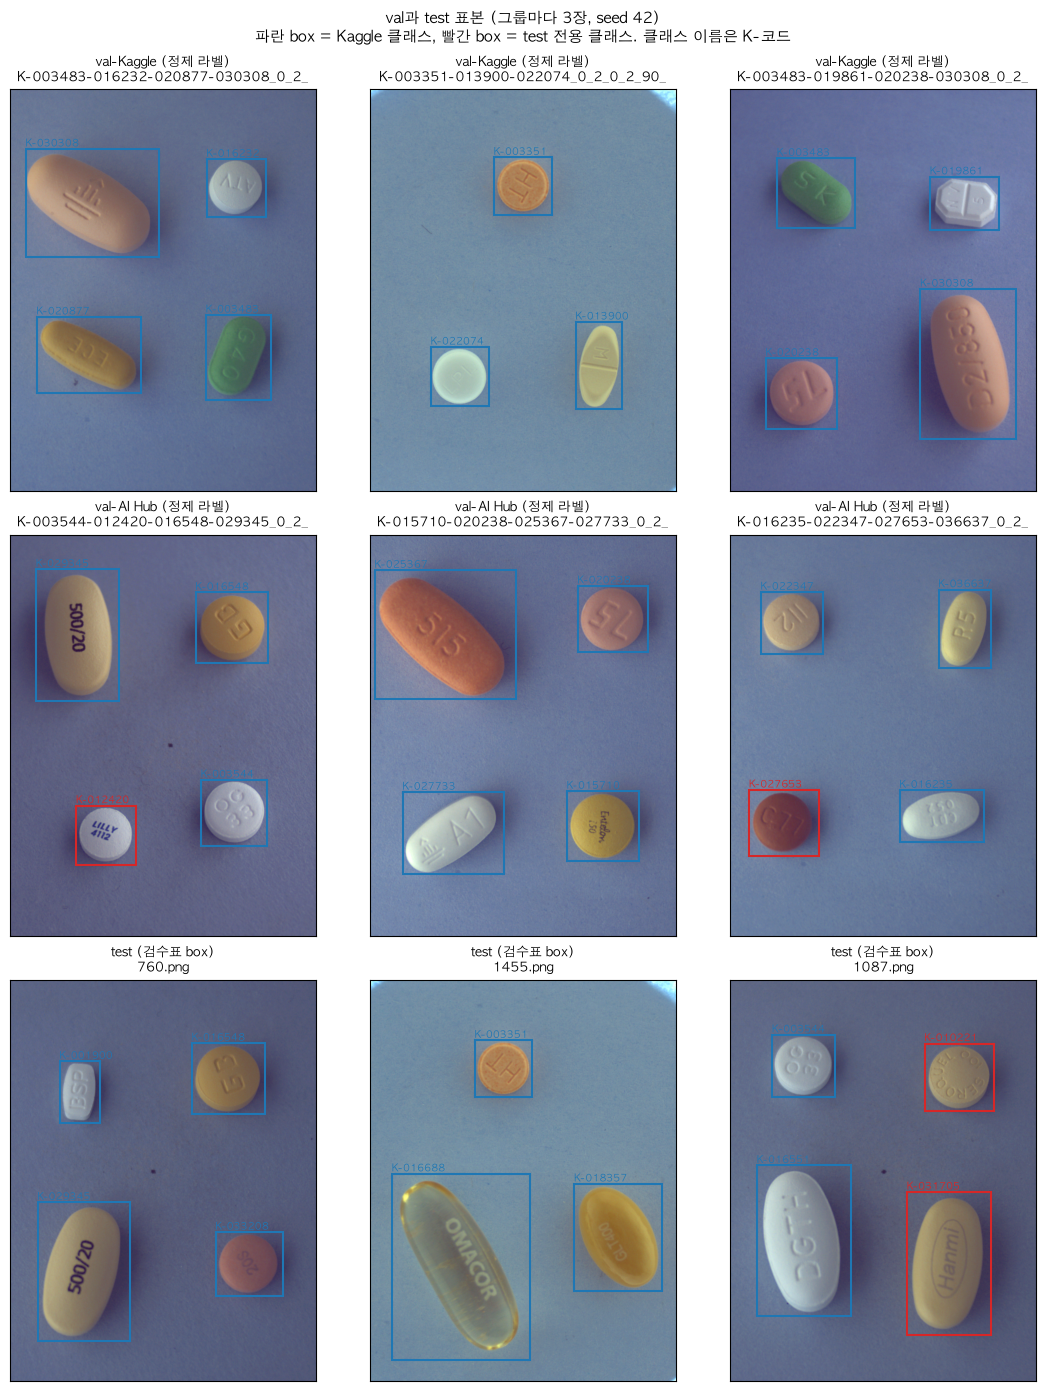

In [ ]:
N_PER_GROUP = 3
val_by_source = {s: [im for im in val_gt['images'] if im['source'] == s] for s in ('kaggle', 'aihub')}
gt_boxes = collections.defaultdict(list)
for ann in val_gt['annotations']:
    gt_boxes[ann['image_id']].append((ann['category_id'], ann['bbox']))
test_boxes = collections.defaultdict(list)
for crop in test_crops:
    test_boxes[crop['test_file']].append((crop['category_id'], crop['bbox']))

samples = []
for title, source in (('val-Kaggle (정제 라벨)', 'kaggle'), ('val-AI Hub (정제 라벨)', 'aihub')):
    for im in rng.choice(val_by_source[source], N_PER_GROUP, replace=False):
        samples.append((title, DATA_DIR / IMAGE_DIRS[source] / im['file_name'], gt_boxes[im['id']], im['file_name']))
for f in rng.choice(test_files, N_PER_GROUP, replace=False):
    samples.append(('test (검수표 box)', TEST_IMG_DIR / f, test_boxes[f], f))

fig, axes = plt.subplots(3, N_PER_GROUP, figsize=(N_PER_GROUP * 3.6, 3 * 4.6), layout='constrained')
for ax, (title, path, boxes, name) in zip(axes.flat, samples):
    ax.imshow(Image.open(path).convert('RGB'))
    for c, (x, y, w, h) in boxes:
        color = 'tab:red' if c in TEST_ONLY else 'tab:blue'
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1.5))
        ax.text(x, y - 8, k_code(c), color=color, fontsize=7, ha='left')
    ax.set_title(f'{title}\n{name[:34]}', fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f'val과 test 표본 (그룹마다 {N_PER_GROUP}장, seed {SEED})\n파란 box = Kaggle 클래스, 빨간 box = test 전용 클래스. 클래스 이름은 K-코드', fontsize=11)
save_fig(fig, '1-3_samples')
plt.show()

**인사이트**
- 세 그룹 모두 box가 알약 외곽에 여백 없이 붙어 있다. Kaggle 정제 라벨, AI Hub 정제 라벨, test 검수표 box(1차 모델 예측)의 모양이 눈으로는 구별되지 않는다.
- 배경(연보라 바닥), 조명, 알약 배치(2×2 또는 3개)가 세 그룹에서 같다. test 전용 클래스(빨간 box)도 같은 환경에서 찍혔다.

**결론**
- 눈으로 보이는 라벨 스타일 차이는 없다. 출처 간 box 여백 차이는 4-2에서 수치로 확인한다.

## 2. 클래스 분포
- 목적: val이 test의 클래스 분포를 대표하는지, 대표하지 못하는 클래스가 무엇인지 정한다. (가설 1)
    - 2차 val은 AI Hub 몫을 test 빈도 비율로 나누되, 클래스마다 최소 `VAL_CLASS_FLOOR`개, 최대 그 클래스 AI Hub 객체의 `VAL_CLASS_CAP`까지만 넣었다. (`datasets.select_val`)
    - 대회 점수는 클래스별 AP의 평균이므로, 클래스 하나가 몇 개든 비중은 1/74로 같다. 빈도보다 "val에 그 클래스가 믿을 만큼 있는가"가 중요하다.

### 2-1. 대회 클래스 74개의 split별 객체 수
- 클래스마다 train(Kaggle, AI Hub), val(Kaggle, AI Hub), test(검수표) 객체 수를 센다. test 수가 많은 순서로 놓고 log 축으로 그린다.
    - 위 그림은 val과 test, 아래 그림은 train이다. x축 이름이 빨간색이면 test 전용 클래스이다.

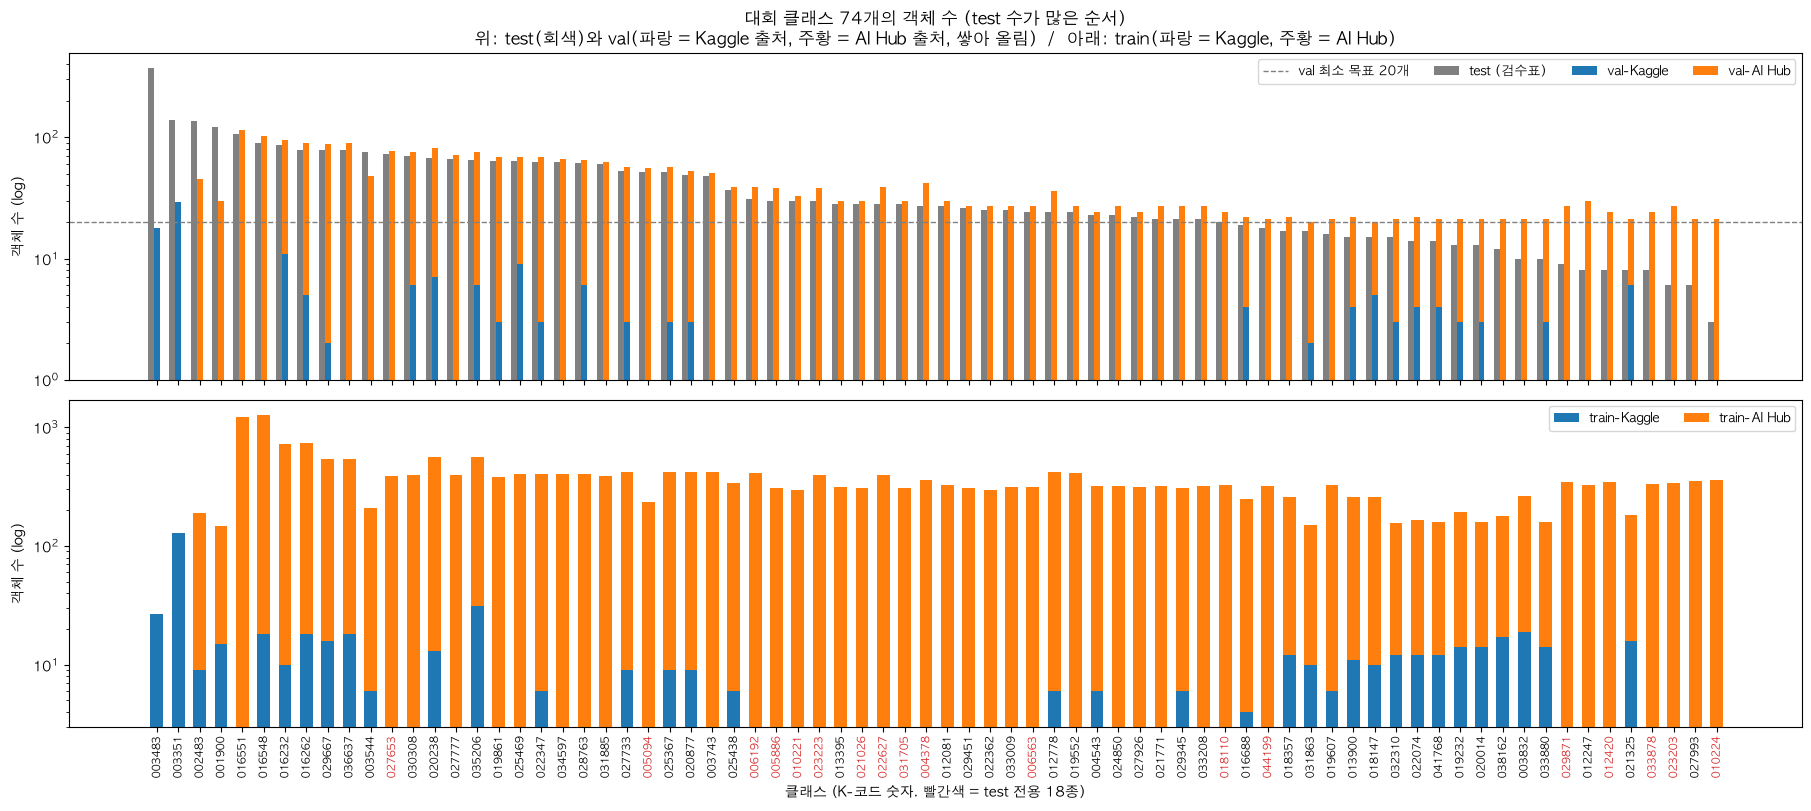

In [ ]:
counts = {key: collections.Counter() for key in ('train-kaggle', 'train-aihub', 'val-kaggle', 'val-aihub')}
for name, im in images.items():
    key = f"{split_of[name]}-{im['source']}"
    for c, _, _ in im['objects']:
        if c in COMPETITION:
            counts[key][c] += 1
counts['test'] = collections.Counter({c: n for c, n in test_counts.items() if c in COMPETITION})
order = sorted(COMPETITION, key=lambda c: (-counts['test'][c], c))
x = np.arange(len(order))

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(18, 8), sharex=True, layout='constrained')
w = 0.28
ax_top.bar(x - w, [counts['test'][c] for c in order], w, color='gray', label='test (검수표)')
ax_top.bar(x, [counts['val-kaggle'][c] for c in order], w, color='tab:blue', label='val-Kaggle')
ax_top.bar(x, [counts['val-aihub'][c] for c in order], w, bottom=[counts['val-kaggle'][c] for c in order], color='tab:orange', label='val-AI Hub')
ax_top.axhline(VAL_CLASS_FLOOR, color='gray', linestyle='--', linewidth=1, label=f'val 최소 목표 {VAL_CLASS_FLOOR}개')
ax_top.set_yscale('log')
ax_top.set_ylabel('객체 수 (log)')
ax_top.set_title('대회 클래스 74개의 객체 수 (test 수가 많은 순서)\n위: test(회색)와 val(파랑 = Kaggle 출처, 주황 = AI Hub 출처, 쌓아 올림)  /  아래: train(파랑 = Kaggle, 주황 = AI Hub)')
ax_top.legend(ncol=4, fontsize=9)
ax_bottom.bar(x, [counts['train-kaggle'][c] for c in order], 0.6, color='tab:blue', label='train-Kaggle')
ax_bottom.bar(x, [counts['train-aihub'][c] for c in order], 0.6, bottom=[counts['train-kaggle'][c] for c in order], color='tab:orange', label='train-AI Hub')
ax_bottom.set_yscale('log')
ax_bottom.set_ylabel('객체 수 (log)')
ax_bottom.set_xticks(x, [k_code(c)[2:] for c in order], rotation=90, fontsize=8)
for tick, c in zip(ax_bottom.get_xticklabels(), order):
    tick.set_color('tab:red' if c in TEST_ONLY else 'black')
ax_bottom.set_xlabel('클래스 (K-코드 숫자. 빨간색 = test 전용 18종)')
ax_bottom.legend(ncol=2, fontsize=9)
save_fig(fig, '2-1_class_counts')
plt.show()

**인사이트**
- val 객체 수는 클래스당 18~114개(중앙값 30개)이다. 74종 중 73종이 최소 목표 20개 이상이고, 유일한 예외는 K-003483(18개)이다.
    - K-003483과 K-003351은 허용된 AI Hub zip에 없는 클래스라서(01 1-6) val-AI Hub가 0이고 val-Kaggle 47장에서만 나온다.
- test 최빈 클래스 K-003483은 test 369개(11.4%)인데 train 27개, val 18개뿐이다. 그래도 5-3에서 이 클래스의 val AP는 0.95 이상이다.
- train은 AI Hub가 클래스당 수백 개(140~1,270개)를 채우고, Kaggle train은 클래스당 3~31개다. test 전용 18종(빨간 이름)은 train·val 모두 AI Hub뿐이다.

**결론**
- 클래스별 val 객체 수는 설계(`select_val`: 최소 20개, AI Hub 객체의 20% 상한)대로 들어가 있다. 빈도 부족으로 val AP를 재지 못하는 클래스는 없다.
- K-003483과 K-003351은 val 근거가 Kaggle 47장뿐이므로, 두 클래스의 val AP는 2~3장 사진의 18~29개 객체에서 나온 값으로 읽는다.

### 2-2. val 비율 vs test 비율
- 클래스별 val 객체 비율(대회 클래스 val 객체 중 그 클래스의 비율)과 test 비율을 log-log 산점도로 비교한다.
    - 스피어만 상관(순위 상관, 1이면 순서가 완전히 같음)을 제목에 적는다.
    - val 수가 상한(AI Hub 객체의 20%)에 걸린 클래스는 빨간 테두리로 표시하고, val/test 비율이 1/3 미만이거나 3배 초과인 클래스에 이름을 적는다.

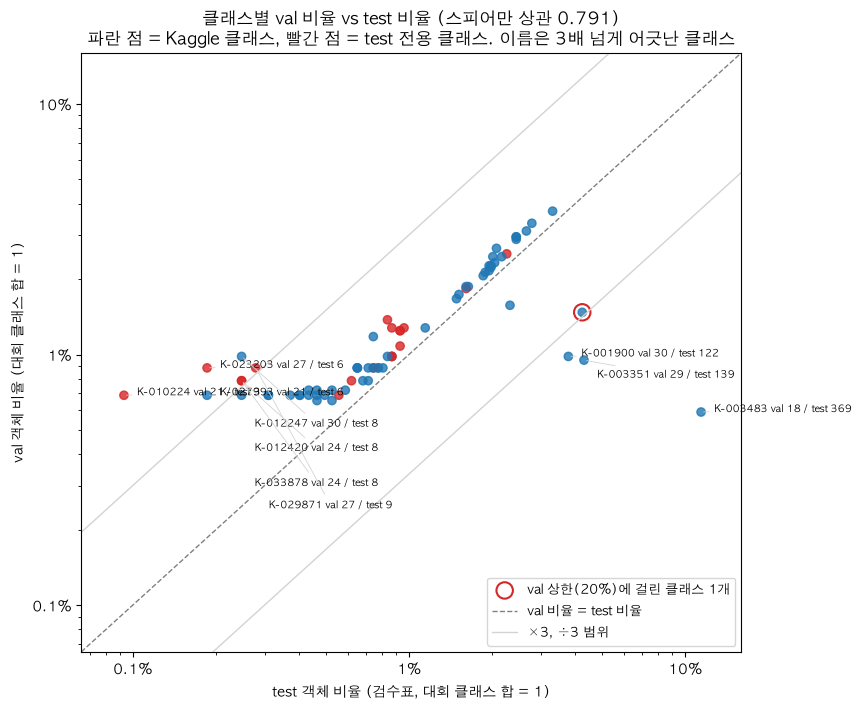

In [ ]:
RATIO_LIMIT = 3  # 이 배수를 넘게 어긋난 클래스에 이름을 적는다
val_total = sum(counts['val-kaggle'][c] + counts['val-aihub'][c] for c in order)
test_total = sum(counts['test'][c] for c in order)
aihub_total = {c: counts['train-aihub'][c] + counts['val-aihub'][c] for c in order}
val_share = np.array([(counts['val-kaggle'][c] + counts['val-aihub'][c]) / val_total for c in order])
test_share = np.array([counts['test'][c] / test_total for c in order])
capped = np.array([aihub_total[c] > 0 and counts['val-aihub'][c] >= int(aihub_total[c] * VAL_CLASS_CAP) for c in order])


def spearman(a, b):
    """스피어만 순위 상관: 두 값의 순위에 대한 피어슨 상관."""
    rank = lambda v: np.argsort(np.argsort(v))
    return np.corrcoef(rank(a), rank(b))[0, 1]


fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
colors = ['tab:red' if c in TEST_ONLY else 'tab:blue' for c in order]
ax.scatter(test_share, val_share, c=colors, s=36, alpha=0.8)
ax.scatter(test_share[capped], val_share[capped], s=140, facecolors='none', edgecolors='tab:red', linewidths=1.5, label=f'val 상한({VAL_CLASS_CAP:.0%})에 걸린 클래스 {capped.sum()}개')
lims = [min(test_share.min(), val_share.min()) * 0.7, max(test_share.max(), val_share.max()) * 1.4]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1, label='val 비율 = test 비율')
ax.plot(lims, [l * RATIO_LIMIT for l in lims], color='lightgray', linewidth=1)
ax.plot(lims, [l / RATIO_LIMIT for l in lims], color='lightgray', linewidth=1, label=f'×{RATIO_LIMIT}, ÷{RATIO_LIMIT} 범위')
placed = []   # 이미 적은 이름의 위치 (log 좌표). 겹치면 아래로 내려 적는다
for c, ts, vs in sorted(zip(order, test_share, val_share), key=lambda t: (t[1], -t[2])):
    if vs / ts > RATIO_LIMIT or ts / vs > RATIO_LIMIT:
        lx, ly = np.log10(ts), np.log10(vs)
        while any(abs(lx - px) < 0.22 and abs(ly - py) < 0.07 for px, py in placed):
            ly -= 0.07
        placed.append((lx, ly))
        ax.annotate(f'{k_code(c)} val {counts["val-kaggle"][c] + counts["val-aihub"][c]} / test {counts["test"][c]}', (ts, vs), xytext=(10 ** lx * 1.12, 10 ** ly),
                    fontsize=7, arrowprops=dict(arrowstyle='-', color='lightgray', linewidth=0.6))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(lims)
ax.set_ylim(lims)
for axis in (ax.xaxis, ax.yaxis):   # log 축 눈금을 퍼센트로 적는다 (수식 폰트의 마이너스 기호 깨짐도 피한다)
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:.1%}' if v < 0.01 else f'{v:.0%}'))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xlabel('test 객체 비율 (검수표, 대회 클래스 합 = 1)')
ax.set_ylabel('val 객체 비율 (대회 클래스 합 = 1)')
ax.set_title(f'클래스별 val 비율 vs test 비율 (스피어만 상관 {spearman(test_share, val_share):.3f})\n파란 점 = Kaggle 클래스, 빨간 점 = test 전용 클래스. 이름은 {RATIO_LIMIT}배 넘게 어긋난 클래스')
ax.legend(fontsize=9, loc='lower right')
save_fig(fig, '2-2_val_vs_test_share')
plt.show()

**인사이트**
- val 비율과 test 비율의 순위 상관은 0.791이다. 대체로 비슷하지만 양 끝이 어긋난다.
- val이 모자란 쪽은 3종이다: K-003483(val 18 / test 369, 비 0.05), K-003351(29 / 139, 0.22), K-001900(30 / 122, 0.26).
    - K-003483·K-003351은 AI Hub에 없어 늘릴 수 없고, K-001900은 AI Hub 객체의 20% 상한에 걸렸다(빨간 테두리).
- val이 넘치는 쪽 7종(K-010224, K-023203, K-012247, K-027993, K-033878, K-029871, K-012420)은 test에 3~9개뿐인 희소 클래스다. 최소 목표 20개 때문에 val 비율이 3~7배 높다.

**결론**
- val의 클래스 비율은 test와 다르지만, 이는 "희소 클래스도 20개 이상 넣는다"는 설계의 결과다. 대회 점수는 클래스별 AP의 단순 평균이라 비율 차이 자체는 점수를 바꾸지 않는다.
- 가설 1의 "분포가 다르다"는 사실이지만, 5-1·5-2에서 val-Kaggle 47장(대회 측 라벨, test와 같은 장면 28장 포함)도 0.99라서 분포 차이로 0.38 손실을 설명할 수 없다. val 구성은 바꾸지 않는다.

### 2-3. 클래스별 val 근거의 출처
- 대회 클래스 74개를 "val-Kaggle 47장에 있는 클래스"와 "val-AI Hub에만 있는 클래스"로 나누고, 그룹(Kaggle 56종, test 전용 18종)별로 센다.
    - val의 `kaggle` 점수(47장)는 대회 측 라벨로 채점한 값이라 test와 가장 가깝다. 나머지 클래스의 val AP는 우리가 정제한 AI Hub 라벨만 근거이다.

In [ ]:
in_kaggle_val = {c for c in order if counts['val-kaggle'][c] > 0}
in_aihub_val = {c for c in order if counts['val-aihub'][c] > 0}
rows = []
for group_name, group in (('Kaggle 클래스 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)):
    both = group & in_kaggle_val & in_aihub_val
    only_kaggle = group & in_kaggle_val - in_aihub_val
    only_aihub = group & in_aihub_val - in_kaggle_val
    none = group - in_kaggle_val - in_aihub_val
    rows.append([group_name, len(both), len(only_kaggle), len(only_aihub), len(none),
                 f"{sum(counts['val-kaggle'][c] for c in group):,}", f"{sum(counts['val-aihub'][c] for c in group):,}", f"{sum(counts['test'][c] for c in group):,}"])
rows.append(['**합계 74종**', *[f'**{sum(int(r[i]) for r in rows)}**' for i in range(1, 5)],
             f"**{sum(counts['val-kaggle'].values()):,}**", f"**{sum(counts['val-aihub'].values()):,}**", f"**{test_total:,}**"])
show_table(['그룹', 'val-Kaggle과 val-AI Hub 모두 있음', 'val-Kaggle에만', 'val-AI Hub에만', 'val에 없음', 'val-Kaggle 객체', 'val-AI Hub 객체', 'test 객체 (검수표)'], rows)

| 그룹 | val-Kaggle과 val-AI Hub 모두 있음 | val-Kaggle에만 | val-AI Hub에만 | val에 없음 | val-Kaggle 객체 | val-AI Hub 객체 | test 객체 (검수표) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle 클래스 56종 | 28 | 2 | 26 | 0 | 159 | 2,277 | 2,776 |
| test 전용 18종 | 0 | 0 | 18 | 0 | 0 | 617 | 453 |
| **합계 74종** | **28** | **2** | **44** | **0** | **159** | **2,894** | **3,229** |

**인사이트**
- 74종 중 44종(59%)은 val 근거가 AI Hub 정제 라벨뿐이다. Kaggle 클래스 26종 + test 전용 18종이다.
- 28종은 val-Kaggle과 val-AI Hub에 모두 있고, 2종(K-003351, K-003483)은 val-Kaggle에만 있다.
- val-Kaggle 객체는 159개로 val 대회 클래스 객체의 5%다. `kaggle` 점수는 30종 159객체로 잰 값이다.

**결론**
- val 점수의 95%는 우리가 만든 라벨 체계 안에서의 점수다. 대회 측 라벨 기준 점수(`kaggle`)는 30종에서만 측정되고 표본이 작아 ±0.01 차이는 의미가 없다.
- 3차 이후에도 `val`, `kaggle`, `test_only` 세 점수를 함께 보고하고, 모델 선택은 `val`로 하되 Kaggle 점수와의 차이는 6절의 상한으로 해석한다.

## 3. category_id 매핑
- 목적: AI Hub 라벨의 클래스를 `drug_N`(K-코드)으로 읽는 지금 방식(`data.py`)을 계속 믿을지 정한다. (가설 2)
    - 대회 측은 `category_id`를 "JSON 첫 이미지의 `dl_idx`"로 매겼다고 적었다. (DATA.md 데이터 가공 관련 참고사항)
    - 번호가 틀리면 에러 없이 그 클래스 AP만 0이 된다. test 전용 18종은 Kaggle 라벨이 없어 번호를 대회 데이터로 확인할 수 없다.

### 3-1. dl_idx, drug_N, Kaggle category_id 규칙
- AI Hub 원본 JSON에서 클래스(K-코드 폴더)마다 하나를 읽어 `dl_idx`와 `drug_N`의 관계를 세고, Kaggle 원본 JSON에서는 `category_id`와 `dl_idx`, `drug_N`의 관계를 센다.
    - 규칙은 "같음", "K-코드 − 1", "그 밖"으로 나눈다. 대회 클래스만 센다.

In [ ]:
def first_json_per_class(ann_dir):
    """annotation 폴더에서 K-코드 폴더마다 첫 JSON 하나씩 읽어 {category_id: (dl_idx, drug_N 번호, category_id 값)}을 만든다."""
    found = {}
    for folder in sorted(ann_dir.glob('*_json/K-*')):
        digits = folder.name.removeprefix('K-')
        if not digits.isdigit():   # AI Hub 원본의 "K-023319-오류" 같은 폴더는 뺀다 (01 2-4)
            continue
        code_ = int(digits)
        if code_ in found or code_ not in COMPETITION:
            continue
        for path in sorted(folder.glob('*.json')):
            try:
                data = json.loads(path.read_text(encoding='utf-8-sig'))
            except ValueError:
                continue
            image = data['images'][0]
            found[code_] = (int(image['dl_idx']), int(image['drug_N'].removeprefix('K-')), data['annotations'][0]['category_id'])
            break
    return found


def rule(value, code_):
    return '같음' if value == code_ else 'K-코드 − 1' if value == code_ - 1 else '그 밖'


aihub_ids = first_json_per_class(AIHUB_RAW_ANN)
kaggle_ids = first_json_per_class(KAGGLE_RAW_ANN)
rows = []
for source, ids, field in (('AI Hub 원본', aihub_ids, 'dl_idx'), ('AI Hub 원본', aihub_ids, 'drug_N'),
                           ('Kaggle 원본', kaggle_ids, 'dl_idx'), ('Kaggle 원본', kaggle_ids, 'drug_N'), ('Kaggle 원본', kaggle_ids, 'category_id')):
    index = {'dl_idx': 0, 'drug_N': 1, 'category_id': 2}[field]
    for group_name, group in (('Kaggle 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)):
        tally = collections.Counter(rule(ids[c][index], c) for c in group if c in ids)
        examples = [f'{k_code(c)}→{ids[c][index]}' for c in sorted(group) if c in ids and rule(ids[c][index], c) == '그 밖'][:3]
        rows.append([source, field, group_name, sum(c in ids for c in group), tally['같음'], tally['K-코드 − 1'], tally['그 밖'], ', '.join(examples)])
show_table(['출처', '번호 필드', '클래스 그룹', '찾은 클래스 수', '= K-코드', '= K-코드 − 1', '그 밖', '그 밖 예'], rows)

| 출처 | 번호 필드 | 클래스 그룹 | 찾은 클래스 수 | = K-코드 | = K-코드 − 1 | 그 밖 | 그 밖 예 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| AI Hub 원본 | dl_idx | Kaggle 56종 | 54 | 0 | 54 | 0 |  |
| AI Hub 원본 | dl_idx | test 전용 18종 | 18 | 0 | 18 | 0 |  |
| AI Hub 원본 | drug_N | Kaggle 56종 | 54 | 54 | 0 | 0 |  |
| AI Hub 원본 | drug_N | test 전용 18종 | 18 | 18 | 0 | 0 |  |
| Kaggle 원본 | dl_idx | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | dl_idx | test 전용 18종 | 0 | 0 | 0 | 0 |  |
| Kaggle 원본 | drug_N | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | drug_N | test 전용 18종 | 0 | 0 | 0 | 0 |  |
| Kaggle 원본 | category_id | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | category_id | test 전용 18종 | 0 | 0 | 0 | 0 |  |

**인사이트**
- AI Hub 원본의 `dl_idx`는 찾은 72종(Kaggle 54 + test 전용 18) 모두 K-코드 − 1이고, `drug_N`은 모두 K-코드와 같다. 두 그룹의 규칙이 같다.
- Kaggle 원본은 56종 모두 `dl_idx` = `drug_N` = `category_id` = K-코드다. 대회 측이 받은 AI Hub 데이터의 `dl_idx`는 우리가 받은 zip과 달리 K-코드와 같은 값이었다는 뜻이다.
- Kaggle 54종(대회 측이 K-코드로 맞춘 것이 확인된 클래스)과 test 전용 18종에서 `dl_idx` 규칙이 같으므로, 대회 측 변환을 거친 test 전용 클래스 번호도 K-코드일 가능성이 크다.

**결론**
- `data.py`의 `drug_N` → K-코드 매핑을 유지한다. 가설 2(AI Hub category_id 오류)는 아니다.
- test 전용 18종의 번호는 6-4의 `test_only` 진단 제출(0.16171, 0이 아님)로 대회 정답과 같음이 확인됐다.

### 3-2. test 전용 18종의 외형 대조
- test 전용 클래스마다 AI Hub 학습 사진의 crop 2개(우리 라벨)와 test 검수표 crop 2개(사람이 확인한 클래스)를 나란히 놓는다.
    - 두 쪽 알약의 색·모양·각인이 같으면 "AI Hub 사진의 이 알약 = test의 이 알약"이고, 번호 매핑은 그림 밖의 문제(대회 정답 번호)만 남는다.

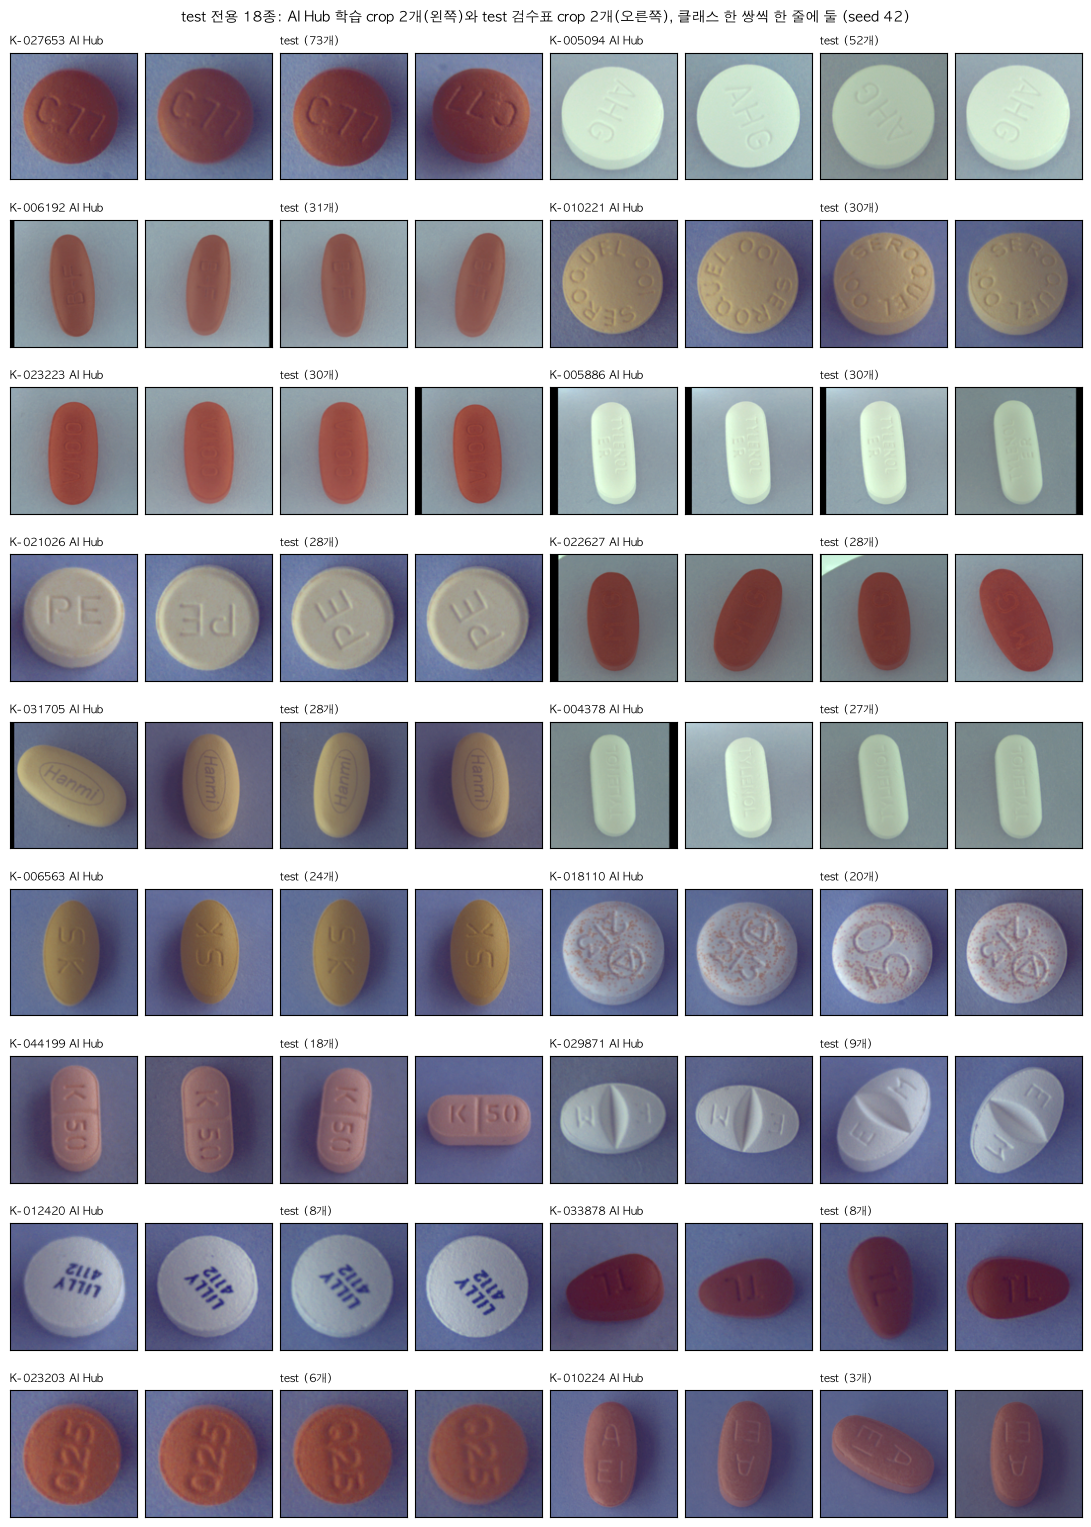

In [ ]:
N_CROPS = 2
test_image_cache = {}


def test_image(f):
    if f not in test_image_cache:
        test_image_cache[f] = Image.open(TEST_IMG_DIR / f).convert('RGB')
    return test_image_cache[f]


aihub_objects = collections.defaultdict(list)   # test 전용 클래스 → [(파일명, box)]
for name, im in images.items():
    if im['source'] == 'aihub':
        for c, box, _ in im['objects']:
            if c in TEST_ONLY:
                aihub_objects[c].append((name, box))
test_objects = collections.defaultdict(list)
for crop in test_crops:
    if crop['category_id'] in TEST_ONLY:
        test_objects[crop['category_id']].append((crop['test_file'], crop['bbox']))

classes = sorted(TEST_ONLY, key=lambda c: -counts['test'][c])
n_rows = (len(classes) + 1) // 2
fig, axes = plt.subplots(n_rows, 2 * N_CROPS * 2, figsize=(2 * N_CROPS * 2 * 1.35, n_rows * 1.7), layout='constrained')
for i, c in enumerate(classes):
    r, base = i // 2, (i % 2) * 2 * N_CROPS
    picks_a = [aihub_objects[c][j] for j in rng.choice(len(aihub_objects[c]), N_CROPS, replace=False)]
    picks_t = [test_objects[c][j] for j in rng.choice(len(test_objects[c]), N_CROPS, replace=False)]
    for j, (name, box) in enumerate(picks_a):
        ax = axes[r, base + j]
        ax.imshow(crop_square(Image.open(DATA_DIR / IMAGE_DIRS['aihub'] / name).convert('RGB'), box))
        ax.set_title(f'{k_code(c)} AI Hub' if j == 0 else '', fontsize=8, loc='left')
    for j, (f, box) in enumerate(picks_t):
        ax = axes[r, base + N_CROPS + j]
        ax.imshow(crop_square(test_image(f), box))
        ax.set_title(f'test ({counts["test"][c]}개)' if j == 0 else '', fontsize=8, loc='left')
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f'test 전용 18종: AI Hub 학습 crop {N_CROPS}개(왼쪽)와 test 검수표 crop {N_CROPS}개(오른쪽), 클래스 한 쌍씩 한 줄에 둘 (seed {SEED})', fontsize=10)
save_fig(fig, '3-2_test_only_gallery')
plt.show()

**인사이트**
- 18종 모두 AI Hub 학습 crop과 test 검수표 crop이 같은 알약이다. 색, 모양, 각인(C77, AHG, SEROQUEL 100, PE, Hanmi, SK, K|50, LILLY 4112 등)이 일치한다.
- AI Hub crop 일부에 검은 띠(사진 가장자리)가 보이는 것은 crop을 정사각형으로 자를 때 사진 밖이 포함된 것이고 라벨 문제가 아니다.

**결론**
- AI Hub 사진의 알약과 test 알약의 대응은 맞다. 번호(3-1)와 생김새(3-2)가 모두 맞으므로 test 전용 18종의 학습 라벨은 그대로 둔다.

## 4. bbox 크기와 입력 분포
- 목적: 출처(Kaggle, AI Hub) 사이에 box 스타일 차이가 있어 보정이 필요한지(가설 3), test 입력이 val과 다른 점이 있는지 정한다.
    - 대회 지표는 IoU 0.75~0.95를 쓰므로 box 여백이 몇 픽셀만 달라도 점수가 크게 바뀐다. (00 8-2: 중앙값 크기 box를 8px 옮기면 0.64)
    - test box는 검수표의 1차 RT-DETR 예측이라 크기 비교에는 쓰고 여백 비교에는 쓰지 않는다.

### 4-1. 클래스별 box 크기
- test 객체 수 상위 24 클래스의 box 짧은 변(너비와 높이 중 작은 값, 픽셀)을 Kaggle 라벨, AI Hub 라벨, test 검수표 box로 나눠 상자 그림으로 본다.
    - 같은 알약은 같은 거리에서 찍혀 크기가 비슷해야 한다. 상자가 크게 어긋나면 그 클래스의 라벨이나 매핑을 의심한다.

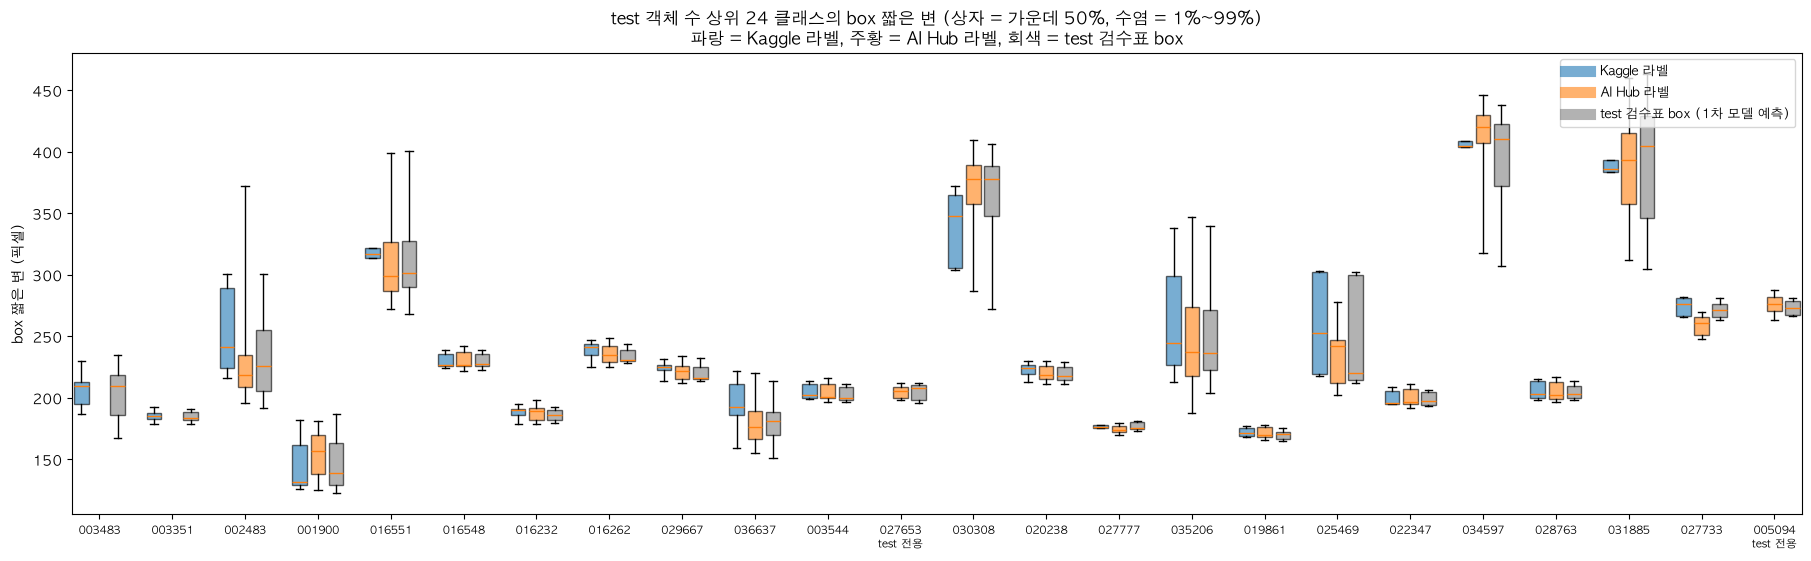

In [ ]:
TOP_K = 24
short_sides = {src: collections.defaultdict(list) for src in ('kaggle', 'aihub', 'test')}
for name, im in images.items():
    for c, (x, y, w, h), _ in im['objects']:
        if c in COMPETITION:
            short_sides[im['source']][c].append(min(w, h))
for crop in test_crops:
    x, y, w, h = crop['bbox']
    short_sides['test'][crop['category_id']].append(min(w, h))

top = order[:TOP_K]
fig, ax = plt.subplots(figsize=(18, 5.5), layout='constrained')
palette = {'kaggle': 'tab:blue', 'aihub': 'tab:orange', 'test': 'gray'}
label = {'kaggle': 'Kaggle 라벨', 'aihub': 'AI Hub 라벨', 'test': 'test 검수표 box (1차 모델 예측)'}
for k, src in enumerate(('kaggle', 'aihub', 'test')):
    data = [short_sides[src][c] if short_sides[src][c] else [np.nan] for c in top]
    parts = ax.boxplot(data, positions=np.arange(TOP_K) * 4 + k, widths=0.8, whis=(1, 99), showfliers=False, patch_artist=True)
    for patch in parts['boxes']:
        patch.set_facecolor(palette[src])
        patch.set_alpha(0.6)
    ax.plot([], [], color=palette[src], linewidth=8, alpha=0.6, label=label[src])
ax.set_xticks(np.arange(TOP_K) * 4 + 1, [f'{k_code(c)[2:]}\n{"test 전용" if c in TEST_ONLY else ""}' for c in top], fontsize=8)
ax.set_ylabel('box 짧은 변 (픽셀)')
ax.set_title(f'test 객체 수 상위 {TOP_K} 클래스의 box 짧은 변 (상자 = 가운데 50%, 수염 = 1%~99%)\n파랑 = Kaggle 라벨, 주황 = AI Hub 라벨, 회색 = test 검수표 box')
ax.legend(loc='upper right', fontsize=9)
save_fig(fig, '4-1_box_short_side')
plt.show()

**인사이트**
- 상위 24 클래스에서 Kaggle 라벨, AI Hub 라벨, test 검수표 box의 상자가 겹친다. 같은 알약은 세 출처에서 같은 크기로 찍혀 있다.
- Kaggle 상자가 유난히 넓은 클래스(K-002483, K-035206, K-025469, K-036637)는 Kaggle box가 9~19개뿐이라 긴 알약이 놓인 각도에 따른 크기 차이가 그대로 보이는 경우다. AI Hub와 test 상자도 같은 범위에 걸쳐 있다.
- K-003483은 AI Hub에 없어 주황 상자가 없다. Kaggle과 test 상자는 겹친다.

**결론**
- 가설 3의 "같은 알약인데 출처마다 box 크기가 다르다"는 아니다. 클래스별 크기 보정은 하지 않는다.

### 4-2. 출처 간 box 여백 차이
- Kaggle 라벨과 AI Hub 라벨이 모두 있는 클래스마다 box 너비·높이의 중앙값을 구해 산점도로 비교한다.
    - 대각선 위에 있으면 두 출처의 여백이 같다. ±5% 선 밖의 클래스에 이름을 적는다.
    - 01 3-1에서는 알약 경계와 box 사이 여백 차이의 중앙값이 0~1px였다.

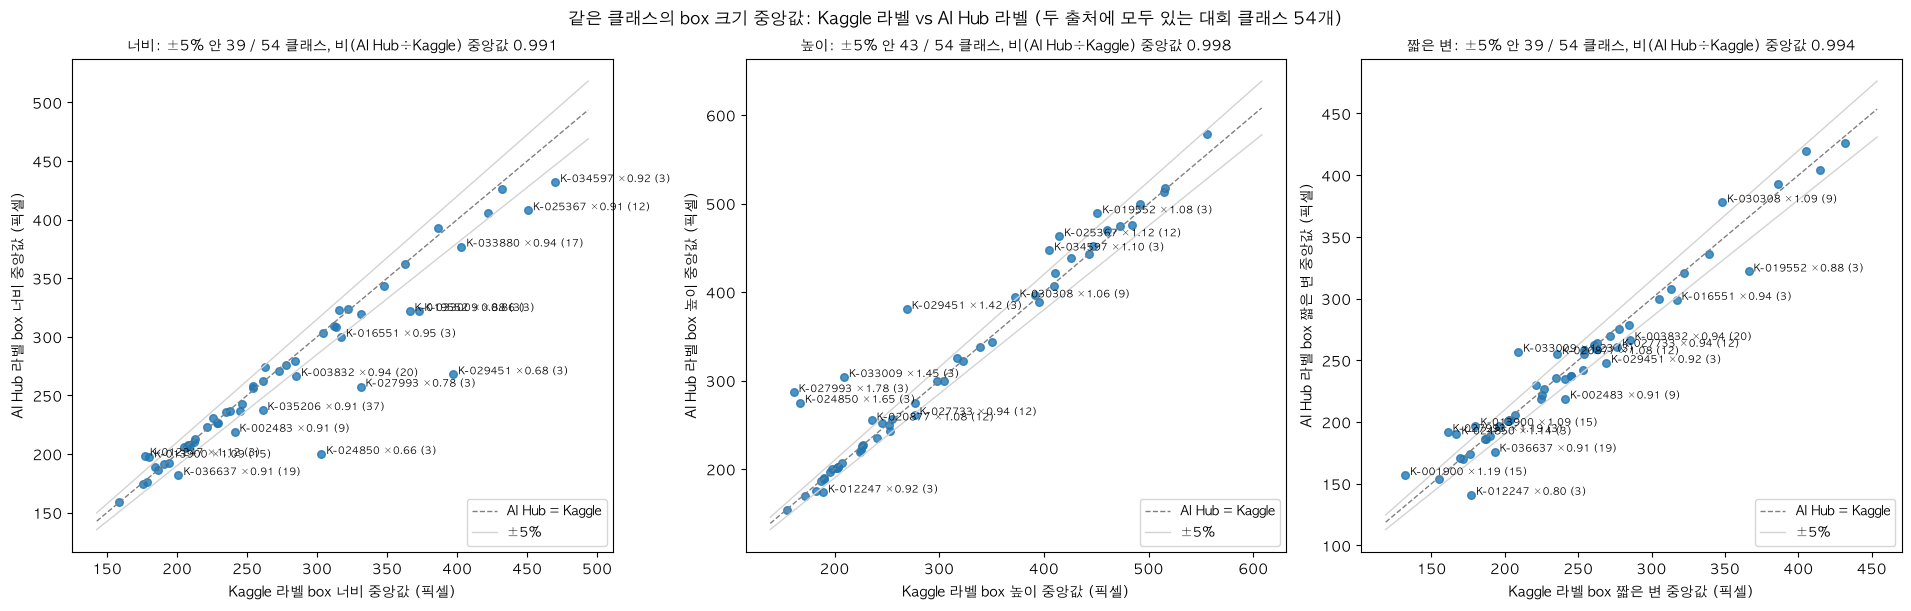

In [ ]:
TOL = 0.05  # 이 비율 밖으로 어긋난 클래스에 이름을 적는다
dims = {src: collections.defaultdict(lambda: {'w': [], 'h': [], 's': []}) for src in ('kaggle', 'aihub')}
for name, im in images.items():
    for c, (x, y, w, h), _ in im['objects']:
        if c in COMPETITION:
            dims[im['source']][c]['w'].append(w)
            dims[im['source']][c]['h'].append(h)
            dims[im['source']][c]['s'].append(min(w, h))   # 짧은 변: 알약이 가로·세로로 놓인 차이에 덜 흔들린다
shared = sorted(c for c in COMPETITION if dims['kaggle'][c]['w'] and dims['aihub'][c]['w'])

fig, axes = plt.subplots(1, 3, figsize=(19, 6), layout='constrained')
for ax, dim, dim_name in zip(axes, ('w', 'h', 's'), ('너비', '높이', '짧은 변')):
    kag = np.array([np.median(dims['kaggle'][c][dim]) for c in shared])
    aih = np.array([np.median(dims['aihub'][c][dim]) for c in shared])
    ratio = aih / kag
    ax.scatter(kag, aih, s=30, color='tab:blue', alpha=0.8)
    lims = [min(kag.min(), aih.min()) * 0.9, max(kag.max(), aih.max()) * 1.05]
    ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1, label='AI Hub = Kaggle')
    ax.plot(lims, [l * (1 + TOL) for l in lims], color='lightgray', linewidth=1)
    ax.plot(lims, [l * (1 - TOL) for l in lims], color='lightgray', linewidth=1, label=f'±{TOL:.0%}')
    for c, kx, ay, r in zip(shared, kag, aih, ratio):
        if abs(r - 1) > TOL:   # 이름 뒤 괄호는 Kaggle box 수. 3개면 중앙값이 각도 하나에 좌우된다
            ax.annotate(f'{k_code(c)} ×{r:.2f} ({len(dims["kaggle"][c][dim])})', (kx, ay), fontsize=7, textcoords='offset points', xytext=(4, 0))
    ax.set_xlabel(f'Kaggle 라벨 box {dim_name} 중앙값 (픽셀)')
    ax.set_ylabel(f'AI Hub 라벨 box {dim_name} 중앙값 (픽셀)')
    ax.set_title(f'{dim_name}: ±{TOL:.0%} 안 {np.sum(np.abs(ratio - 1) <= TOL)} / {len(shared)} 클래스, 비(AI Hub÷Kaggle) 중앙값 {np.median(ratio):.3f}', fontsize=10)
    ax.legend(fontsize=9, loc='lower right')
fig.suptitle(f'같은 클래스의 box 크기 중앙값: Kaggle 라벨 vs AI Hub 라벨 (두 출처에 모두 있는 대회 클래스 {len(shared)}개)')
save_fig(fig, '4-2_box_margin_by_source')
plt.show()

**인사이트**
- Kaggle 라벨과 AI Hub 라벨의 box 크기 중앙값 비(AI Hub ÷ Kaggle)는 너비 0.991, 높이 0.998, 짧은 변 0.994로 1에 붙어 있다. 체계적인 여백 차이는 없다.
- ±5% 밖의 클래스는 너비 15개, 높이 11개, 짧은 변 15개다. 대부분 Kaggle box가 3~9개뿐인 클래스(괄호 안 수)이거나 긴 알약이 비스듬히 놓여 축에 맞춘 box가 커진 경우다.
    - 예: K-024850은 너비 ×0.66, 높이 ×1.65로 Kaggle 사진에서 알약이 90° 돌아가 있다. 짧은 변으로 보면 ×1.14다.
- 01 3-1(알약 경계와 box 사이 여백 차이 중앙값 0~1px)과 같은 결론이다.

**결론**
- 출처 간 box 스타일 보정은 하지 않는다. 학습 라벨의 여백은 Kaggle과 AI Hub가 같다.
- 5-2에서 val-Kaggle과 val-AI Hub의 IoU 0.95 AP가 비슷하게 높은 것도 이 결과와 맞는다.

### 4-3. 이미지당 알약 수와 밝기
- 그룹(train-Kaggle, train-AI Hub, val-Kaggle, val-AI Hub, test)별로 이미지당 알약 수의 비율과 이미지 평균 밝기(회색조 0~255, 1/16로 줄인 사진의 평균)의 분포를 비교한다.
    - AI Hub와 test는 seed를 고정해 그룹당 최대 500장을 뽑는다. 밝기는 `runs/eda_raewoo/cache/03_brightness.json`에 저장해 다시 실행할 때 건너뛴다.
- 실행 시간: 처음 실행할 때 약 1분 (이미지 읽기)

밝기 계산 0초 (1,732장)


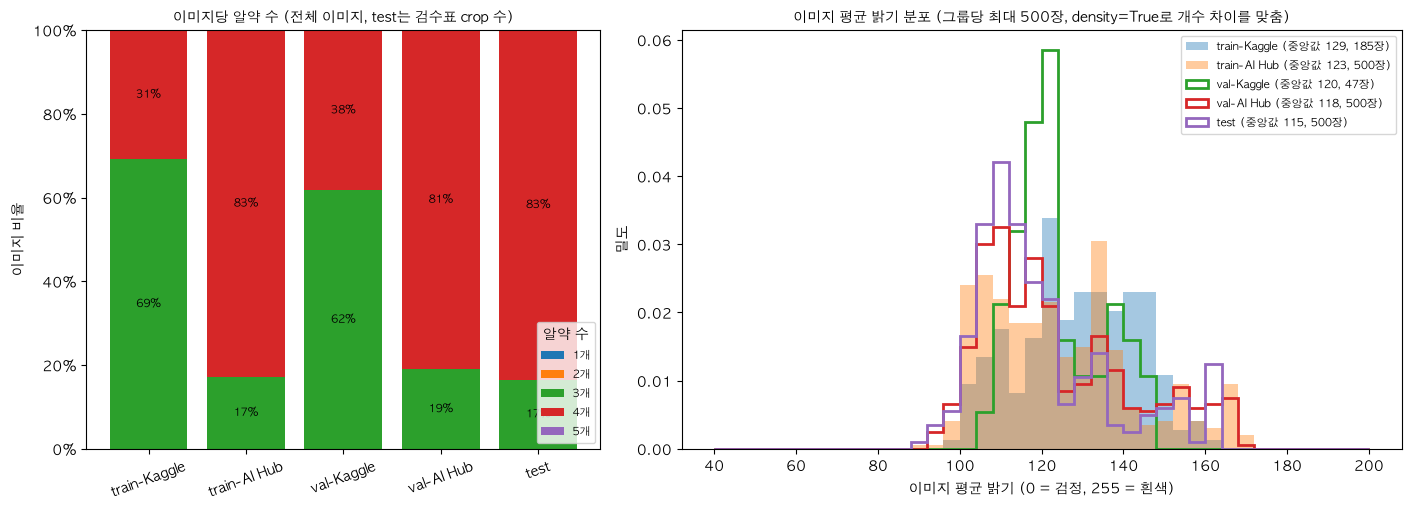

In [ ]:
N_SAMPLE = 500
BRIGHTNESS_CACHE = CACHE_DIR / '03_brightness.json'
brightness = json.loads(BRIGHTNESS_CACHE.read_text()) if BRIGHTNESS_CACHE.exists() else {}

groups = {'train-Kaggle': [], 'train-AI Hub': [], 'val-Kaggle': [], 'val-AI Hub': [], 'test': []}
for name, im in images.items():
    groups[f"{split_of[name]}-{'Kaggle' if im['source'] == 'kaggle' else 'AI Hub'}"].append((DATA_DIR / IMAGE_DIRS[im['source']] / name, len(im['objects'])))
groups['test'] = [(TEST_IMG_DIR / f, len(test_boxes[f])) for f in test_files]
sampled = {g: [items[i] for i in rng.choice(len(items), min(N_SAMPLE, len(items)), replace=False)] for g, items in groups.items()}


def mean_brightness(path):
    key = str(path.relative_to(PROJECT_ROOT))
    if key not in brightness:
        with Image.open(path) as image:
            brightness[key] = float(np.asarray(image.convert('L').resize((IMG_W // 16, IMG_H // 16))).mean())
    return brightness[key]


start = time.perf_counter()
values = {g: np.array([mean_brightness(p) for p, _ in items]) for g, items in sampled.items()}
BRIGHTNESS_CACHE.write_text(json.dumps(brightness))
print(f'밝기 계산 {time.perf_counter() - start:.0f}초 ({sum(len(v) for v in values.values()):,}장)')

fig, (ax_count, ax_bright) = plt.subplots(1, 2, figsize=(14, 5), layout='constrained', width_ratios=[1, 1.4])
pill_bins = [1, 2, 3, 4, 5]
bottom = np.zeros(len(groups))
for n in pill_bins:
    share = np.array([np.mean([k == n for _, k in items]) for items in groups.values()])
    bars = ax_count.bar(list(groups), share, bottom=bottom, label=f'{n}개')
    for b, s in zip(bars, share):
        if s >= 0.04:
            ax_count.text(b.get_x() + b.get_width() / 2, b.get_y() + s / 2, f'{s:.0%}', ha='center', va='center', fontsize=8)
    bottom += share
ax_count.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax_count.set_ylabel('이미지 비율')
ax_count.set_title('이미지당 알약 수 (전체 이미지, test는 검수표 crop 수)', fontsize=10)
ax_count.legend(title='알약 수', fontsize=8, loc='lower right')
ax_count.tick_params(axis='x', rotation=20)
bins = np.linspace(40, 200, 41)
for (g, v), style in zip(values.items(), ['bar', 'bar', 'step', 'step', 'step']):
    if style == 'bar':
        ax_bright.hist(v, bins=bins, density=True, alpha=0.4, label=f'{g} (중앙값 {np.median(v):.0f}, {len(v)}장)')
    else:
        ax_bright.hist(v, bins=bins, density=True, histtype='step', linewidth=2, label=f'{g} (중앙값 {np.median(v):.0f}, {len(v)}장)')
ax_bright.set_xlabel('이미지 평균 밝기 (0 = 검정, 255 = 흰색)')
ax_bright.set_ylabel('밀도')
ax_bright.set_title(f'이미지 평균 밝기 분포 (그룹당 최대 {N_SAMPLE}장, density=True로 개수 차이를 맞춤)', fontsize=10)
ax_bright.legend(fontsize=8)
save_fig(fig, '4-3_pills_and_brightness')
plt.show()

**인사이트**
- 이미지당 알약 수: Kaggle 사진은 3개가 많고(train 69%, val 62%), AI Hub와 test는 4개가 81~83%다. test는 AI Hub와 같은 구성이다.
- 평균 밝기 중앙값은 test 115 < val-AI Hub 118 < val-Kaggle 120 < train-AI Hub 123 < train-Kaggle 129다. test가 가장 어둡지만 분포(90~170)는 다섯 그룹이 겹친다.
    - test의 밝기 분포는 val-AI Hub(빨간 선)와 가장 비슷하다.

**결론**
- 입력 분포(알약 수, 밝기)에서 test는 Kaggle train보다 AI Hub 쪽에 가깝고, val-AI Hub가 test를 잘 대표한다. 밝기 보정이나 증강은 추가하지 않는다.
- test가 조금 어둡다는 점은 모델이 더 어두운 AI Hub 사진을 이미 학습했으므로 원인 후보에서 뺀다.

## 5. 2차 모델 재현
- 목적: 점수 손실이 모델 쪽에 있는지, val과 test 검수표로 볼 수 있는 한계까지 확인한다.
    - 로컬 가중치는 2차 v3 e10 세 모델(`runs/models/exp2_v3_{yolo26s,rtdetr-l,frcnn}_e10_s0_best.pt`)이다. 추론 설정은 2차 노트북과 같다.
        - Ultralytics: `predict(conf=0.001, imgsz=640)`, NMS IoU 0.7, 이미지당 최대 300개
        - Faster R-CNN: 입력 640, `score_thresh 0.001`, NMS 0.5, 이미지당 최대 100개, 라벨 = `classes.csv`의 `idx_v3 + 1` (2차 F-RCNN 노트북 `class_map.csv`와 같은 규칙)
    - 예측은 `runs/eda_raewoo/cache/03_val_pred_<모델>.json`에 저장해 다시 실행할 때 건너뛴다.

### 5-1. val 점수 재현
- 세 모델로 val 1,000장을 추론해 `evaluate_val`로 점수 3개(val, kaggle 47장, test_only)를 다시 재고 기록된 값과 비교한다.
- 실행 시간: Apple GPU(mps)에서 처음 실행할 때 약 5~15분

In [ ]:
RECORDED = {'yolo26s': {'val': 0.9901, 'kaggle': None, 'test_only': None},        # origin/exp/cy-yolo26-exp2 03 노트북 cell 41 (v3 e10)
            'rtdetr-l': {'val': None, 'kaggle': None, 'test_only': None},
            'frcnn': torch.load(WEIGHTS['frcnn'], map_location='cpu', weights_only=False)['scores']}  # 체크포인트에 기록된 값


def cached_predictions(name, make):
    """예측을 캐시 JSON에서 읽고, 없으면 make()로 만들어 저장한다."""
    path = CACHE_DIR / f'03_val_pred_{name}.json'
    if path.exists():
        return json.loads(path.read_text())
    start = time.perf_counter()
    predictions = make()
    path.write_text(json.dumps(predictions))
    print(f'{name}: val {len(val_files):,}장 추론 {time.perf_counter() - start:.0f}초, 예측 {len(predictions):,}개')
    return predictions


def ultralytics_predictions(name):
    from ultralytics import RTDETR, YOLO
    model = (RTDETR if name.startswith('rtdetr') else YOLO)(str(WEIGHTS[name]))
    results = model.predict(str(VAL_IMG_DIR), conf=0.001, imgsz=640, device=str(DEVICE), stream=True, verbose=False)
    return predictions_from_ultralytics(results)


def frcnn_predictions(batch_size=4):
    from torchvision.models.detection import fasterrcnn_resnet50_fpn
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    from torchvision.ops import FrozenBatchNorm2d

    def freeze_batchnorm(module):
        """BatchNorm2d를 eps 0인 FrozenBatchNorm2d로 바꾼다. 값은 뒤에서 체크포인트로 채운다. (2차 F-RCNN 노트북과 같다)"""
        for child_name, child in list(module.named_children()):
            if isinstance(child, torch.nn.BatchNorm2d):
                setattr(module, child_name, FrozenBatchNorm2d(child.num_features, eps=0.0))
            elif isinstance(child, FrozenBatchNorm2d):
                child.eps = 0.0
            else:
                freeze_batchnorm(child)

    checkpoint = torch.load(WEIGHTS['frcnn'], map_location='cpu', weights_only=False)
    config = checkpoint['config']
    category_of = {idx + 1: c for idx, c in enumerate(class_table['classes'])}   # 모델 label(0은 배경) → K-코드
    model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=config['image_size'], max_size=config['image_size'])
    freeze_batchnorm(model)
    model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, len(category_of) + 1)
    model.roi_heads.score_thresh = config['score_threshold']
    model.roi_heads.nms_thresh = config['nms_iou']
    model.roi_heads.detections_per_img = config['max_detections']
    model.load_state_dict(checkpoint['model'])
    model.to(DEVICE).eval()
    predictions = []
    with torch.inference_mode():
        for i in range(0, len(val_files), batch_size):
            batch = val_files[i:i + batch_size]
            tensors = [torch.from_numpy(np.asarray(Image.open(VAL_IMG_DIR / f).convert('RGB'), dtype=np.uint8)).permute(2, 0, 1).to(DEVICE).float().div(255) for f in batch]
            for f, output in zip(batch, model(tensors)):
                for box, label, score in zip(output['boxes'].tolist(), output['labels'].tolist(), output['scores'].tolist()):
                    predictions.append({'file_name': f, 'category_id': category_of[label], 'bbox': xyxy_to_xywh(box), 'score': score})
    return predictions


val_predictions = {name: cached_predictions(name, (lambda n=name: ultralytics_predictions(n)) if name != 'frcnn' else frcnn_predictions) for name in WEIGHTS}
val_scores = {name: evaluate_val(preds, val_gt) for name, preds in val_predictions.items()}
fmt = lambda v: '-' if v is None else f'{v:.4f}'
rows = [[name, f"{len(val_predictions[name]):,}", fmt(s['val']), fmt(RECORDED[name]['val']), fmt(s['kaggle']), fmt(RECORDED[name]['kaggle']), fmt(s['test_only']), fmt(RECORDED[name]['test_only'])]
        for name, s in val_scores.items()]
show_table(['모델 (v3 e10)', '예측 수 (conf 0.001)', 'val 재현', 'val 기록', 'kaggle 47장 재현', 'kaggle 기록', 'test_only 재현', 'test_only 기록'], rows)

| 모델 (v3 e10) | 예측 수 (conf 0.001) | val 재현 | val 기록 | kaggle 47장 재현 | kaggle 기록 | test_only 재현 | test_only 기록 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| yolo26s | 6,221 | 0.9900 | 0.9901 | 0.9920 | - | 0.9894 | - |
| rtdetr-l | 300,000 | 0.9872 | - | 0.9971 | - | 0.9853 | - |
| frcnn | 5,602 | 0.9949 | 0.9949 | 0.9969 | 0.9969 | 0.9950 | 0.9950 |

**인사이트**
- 세 모델의 val 점수가 재현된다. F-RCNN은 세 점수가 체크포인트 기록과 소수 넷째 자리까지 같고(0.9949 / 0.9969 / 0.9950), YOLO26s는 0.9900으로 기록 0.9901과 0.0001 차이다. RT-DETR-l은 0.9872다(기록 없음).
- `kaggle` 47장 점수는 0.992~0.997로 `val`보다 오히려 높다. 대회 측 라벨로 채점해도 모델은 거의 완벽하다.
- RT-DETR 예측은 300,000개(이미지당 300개)다. RT-DETR은 NMS 없이 쿼리 300개를 모두 내기 때문이고, 낮은 score 예측은 AP에 영향이 없다(6-4 conf≥0.5 제출과 같은 이유).

**결론**
- 로컬 추론 파이프라인은 2차 실험과 같다. 이후 5-2~6-1의 예측을 2차 결과의 대리로 쓴다.
- val 0.99는 모델·방법에 관계없이 재현되므로, 0.61과의 차이는 모델이 아니라 val이 보지 못하는 곳에 있다.

### 5-2. IoU 기준별·출처별 AP
- 모델마다 IoU 기준 0.75, 0.80, 0.85, 0.90, 0.95 각각의 AP(대회 클래스 평균)를 val-Kaggle 47장과 val-AI Hub 953장으로 나눠 그린다.
    - 대회 점수는 이 다섯 값의 평균이다. 0.95에서만 떨어지면 box가 1~2px 수준으로만 어긋난다는 뜻이고, 0.75부터 낮으면 놓침이나 클래스 오류가 있다는 뜻이다.

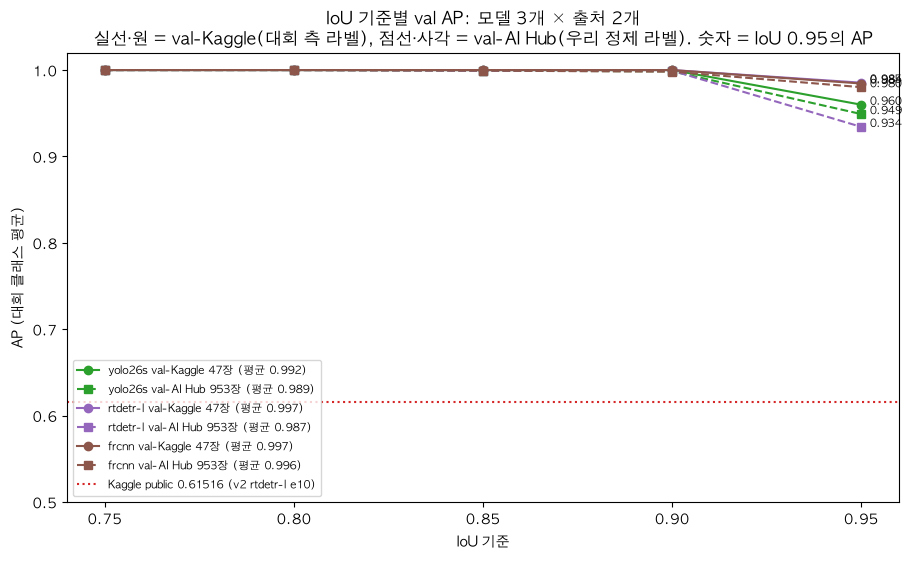

In [ ]:
source_ids = {s: {im['id'] for im in val_gt['images'] if im['source'] == s} for s in ('kaggle', 'aihub')}
kept_predictions = {name: drop_ignored(preds, val_gt) for name, preds in val_predictions.items()}   # evaluate_val과 같은 무시 규칙
curves = {}
for name, preds in kept_predictions.items():
    for s, ids in source_ids.items():
        precision, _ = coco_precision(val_gt, preds, image_ids=ids, category_ids=COMPETITION)
        curves[(name, s)] = ap_by_threshold(precision)

fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
colors = {'yolo26s': 'tab:green', 'rtdetr-l': 'tab:purple', 'frcnn': 'tab:brown'}
for (name, s), aps in curves.items():
    ax.plot(IOU_THRESHOLDS, aps, marker='o' if s == 'kaggle' else 's', linestyle='-' if s == 'kaggle' else '--', color=colors[name],
            label=f"{name} {'val-Kaggle 47장' if s == 'kaggle' else 'val-AI Hub 953장'} (평균 {aps.mean():.3f})")
    ax.annotate(f'{aps[-1]:.3f}', (IOU_THRESHOLDS[-1], aps[-1]), fontsize=8, textcoords='offset points', xytext=(6, 0))
ax.axhline(KAGGLE_SCORES['원본'], color='tab:red', linestyle=':', linewidth=1.5, label=f"Kaggle public {KAGGLE_SCORES['원본']} (v2 rtdetr-l e10)")
ax.set_xticks(IOU_THRESHOLDS)
ax.set_xlabel('IoU 기준')
ax.set_ylabel('AP (대회 클래스 평균)')
ax.set_ylim(0.5, 1.02)
ax.set_title('IoU 기준별 val AP: 모델 3개 × 출처 2개\n실선·원 = val-Kaggle(대회 측 라벨), 점선·사각 = val-AI Hub(우리 정제 라벨). 숫자 = IoU 0.95의 AP')
ax.legend(fontsize=8, loc='lower left')
save_fig(fig, '5-2_ap_by_iou_source')
plt.show()

**인사이트**
- IoU 기준 0.75, 0.80, 0.85, 0.90에서는 세 모델, 두 출처 모두 AP 1.000이다. 놓침이나 클래스 오류가 없다.
- 0.95에서만 떨어진다: val-AI Hub는 RT-DETR 0.934, YOLO26s 0.949, F-RCNN 0.980이고 val-Kaggle은 0.960~0.984다.
    - 우리 라벨 기준으로 box 오차는 1~2px 수준이다(0.95를 넘기려면 200px box에서 2~3px 안에 들어야 한다).
- 대회 측 라벨(val-Kaggle)과 우리 정제 라벨(val-AI Hub)의 곡선 모양이 같다. 라벨 출처에 따른 차이가 없다.
- Kaggle 실측 0.615(빨간 점선)는 어느 곡선과도 멀다. 0.615가 나오려면 0.90·0.95에서 거의 0이거나 0.75부터 떨어져야 한다.

**결론**
- val에서 IoU 기준별로 봐도 손실은 보이지 않는다. 점수를 잃는 곳은 val 라벨(대회 측 train 라벨 포함)과 다른 어떤 것, 즉 test 정답 자체다.
- 3차 이후 val 비교는 IoU 0.95 AP를 따로 기록한다. 나머지 기준은 모두 1.0이라 차이가 나지 않는다.

### 5-3. 클래스별 val AP
- 모델마다 클래스별 val AP(IoU 0.75~0.95 평균)를 val 객체 수에 대해 산점도로 그린다.
    - AP가 0.95 아래인 클래스에 이름을 적는다. val 객체가 적은 클래스의 AP는 한두 개의 오류로 크게 흔들린다.

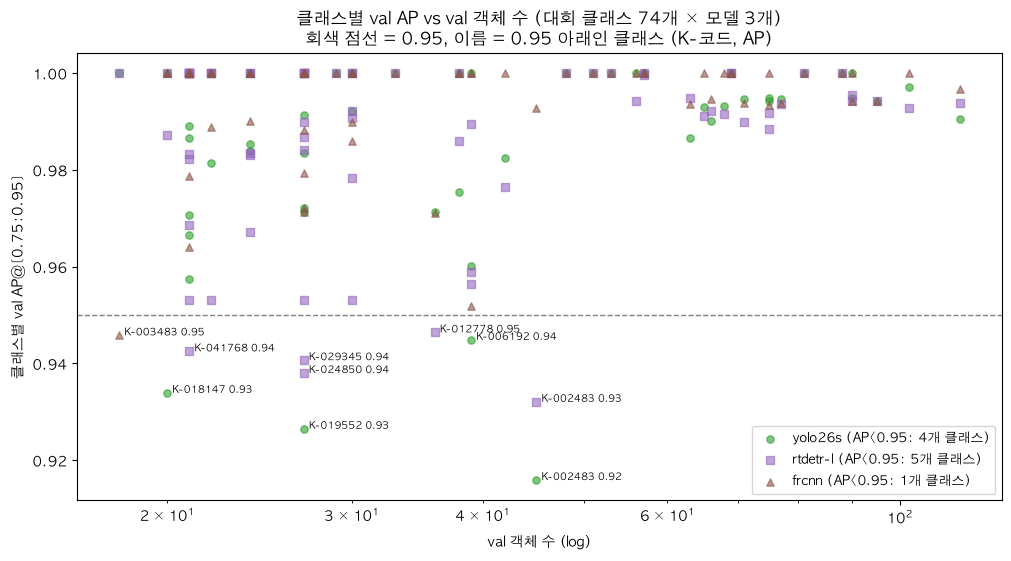

In [ ]:
AP_MARK = 0.95
val_counts = collections.Counter(a['category_id'] for a in val_gt['annotations'] if a['category_id'] in COMPETITION)
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
markers = {'yolo26s': 'o', 'rtdetr-l': 's', 'frcnn': '^'}
low = set()
for name, scores in val_scores.items():
    xs = [val_counts[c] for c in scores['per_class']]
    ys = list(scores['per_class'].values())
    ax.scatter(xs, ys, marker=markers[name], s=28, alpha=0.6, color=colors[name], label=f'{name} (AP<{AP_MARK}: {sum(y < AP_MARK for y in ys)}개 클래스)')
    for c, ap in scores['per_class'].items():
        if ap < AP_MARK:
            low.add(c)
            ax.annotate(f'{k_code(c)} {ap:.2f}', (val_counts[c], ap), fontsize=7, textcoords='offset points', xytext=(4, 0))
ax.axhline(AP_MARK, color='gray', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('val 객체 수 (log)')
ax.set_ylabel('클래스별 val AP@[0.75:0.95]')
ax.set_title(f'클래스별 val AP vs val 객체 수 (대회 클래스 74개 × 모델 3개)\n회색 점선 = {AP_MARK}, 이름 = {AP_MARK} 아래인 클래스 (K-코드, AP)')
ax.legend(fontsize=9, loc='lower right')
save_fig(fig, '5-3_per_class_ap')
plt.show()

**인사이트**
- 클래스별 val AP는 0.92~1.00이다. 0.95 아래인 클래스는 YOLO26s 4개, RT-DETR 5개, F-RCNN 1개이고 모두 val 객체가 45개 이하인 클래스다.
    - 가장 낮은 값은 K-002483(YOLO26s 0.92, RT-DETR 0.93), K-019552(YOLO26s 0.93), K-018147(YOLO26s 0.93)이다.
- 검수표 대리 채점에서 유일하게 혼동된 짝(K-012778 ↔ K-019552, Notion 2-1)이 여기서도 0.95 아래에 있다.
- val 객체 60개 이상인 클래스는 세 모델 모두 0.98 이상이다.

**결론**
- val에서 특별히 못 맞히는 클래스는 없다. 클래스 불균형이 지금 점수를 막는 원인이 아니다.
- 3차에서 클래스별로 볼 때는 K-002483, K-019552, K-012778, K-018147을 모니터링 클래스로 둔다.

### 5-4. 제출 CSV의 검수표 대리 채점
- 제출 파일 2개(0.61516, 0.61558)를 test 검수표를 정답으로 채점한다.
    - IoU 0.5 AP: 검수표 box는 1차 모델 예측이라 느슨한 기준으로 검출과 분류만 본다.
    - 알약별 클래스 일치율: 검수표 알약마다 IoU 0.5 이상으로 겹친 예측 중 score가 가장 높은 것의 클래스가 같은 비율. 겹친 예측이 없으면 "놓침"이다.
    - IoU 중앙값: 그 가장 높은 예측과 검수표 box의 IoU. 1차 모델 box와 2차 모델 box가 얼마나 같은지를 뜻한다.

In [ ]:
PROXY_IOU = 0.5
test_gt = {'images': [{'id': int(Path(f).stem), 'file_name': f, 'width': IMG_W, 'height': IMG_H} for f in test_files],
           'annotations': [{'id': i + 1, 'image_id': int(Path(c['test_file']).stem), 'category_id': c['category_id'], 'bbox': c['bbox'],
                            'area': c['bbox'][2] * c['bbox'][3], 'iscrowd': 0} for i, c in enumerate(test_crops)],
           'categories': [{'id': c, 'competition': 1} for c in sorted(COMPETITION)]}
rows = []
for run, preds in submissions.items():
    by_file = collections.defaultdict(list)
    for p in preds:
        by_file[p['file_name']].append(p)
    ap = {g: ap_by_threshold(coco_precision(test_gt, preds, category_ids=group, iou_thresholds=[PROXY_IOU])[0])[0]
          for g, group in (('all', COMPETITION), ('kaggle', KAGGLE_CLASSES), ('test_only', TEST_ONLY))}
    matched, missed, ious = {'kaggle': [], 'test_only': []}, {'kaggle': 0, 'test_only': 0}, []
    for crop in test_crops:
        g = 'test_only' if crop['category_id'] in TEST_ONLY else 'kaggle'
        candidates = [p for p in by_file[crop['test_file']] if box_iou(p['bbox'], crop['bbox']) >= PROXY_IOU]
        if not candidates:
            missed[g] += 1
            continue
        best = max(candidates, key=lambda p: p['score'])
        matched[g].append(best['category_id'] == crop['category_id'])
        ious.append(box_iou(best['bbox'], crop['bbox']))
    rows.append([run, f'{SUBMISSIONS[run][1]:.5f}', f"{len(preds):,} ({len(preds) / len(test_files):.0f}/장)", f"{ap['all']:.3f}", f"{ap['kaggle']:.3f}", f"{ap['test_only']:.3f}",
                 f"{np.mean(matched['kaggle']):.1%}", f"{np.mean(matched['test_only']):.1%}", f"{missed['kaggle'] + missed['test_only']}", f'{np.median(ious):.3f}'])
show_table(['제출', 'Kaggle public', '예측 수', f'AP@{PROXY_IOU} 전체', f'AP@{PROXY_IOU} Kaggle 56종', f'AP@{PROXY_IOU} test 전용 18종', '클래스 일치 Kaggle', '클래스 일치 test 전용', '놓친 알약', '검수표 box와 IoU 중앙값'], rows)

| 제출 | Kaggle public | 예측 수 | AP@0.5 전체 | AP@0.5 Kaggle 56종 | AP@0.5 test 전용 18종 | 클래스 일치 Kaggle | 클래스 일치 test 전용 | 놓친 알약 | 검수표 box와 IoU 중앙값 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| v2 rtdetr-l e10 | 0.61516 | 90,354 (107/장) | 0.996 | 0.995 | 1.000 | 99.8% | 100.0% | 0 | 0.979 |
| v4 rtdetr-l e5 | 0.61558 | 173,409 (206/장) | 0.996 | 0.994 | 1.000 | 99.7% | 100.0% | 0 | 0.978 |

**인사이트**
- 두 제출 모두 검수표 기준 AP@0.5 0.996(Kaggle 56종 0.994~0.995, test 전용 1.000), 클래스 일치 Kaggle 99.7~99.8%·test 전용 100%, 놓친 알약 0개다.
- 1차 모델 box와의 IoU 중앙값은 0.978~0.979다. 대회 측 train 라벨로만 학습한 1차 모델과 2차 모델이 test에서 거의 같은 box를 그린다.
- v4 e5는 이미지당 206개, v2 e10은 107개를 냈지만 점수(0.61558 vs 0.61516)와 대리 채점이 같다.

**결론**
- 우리 라벨 기준으로 모델은 test에서도 검출·분류가 완벽하다. 손실은 IoU 0.75~0.95 구간의 box 정밀도이거나, 대회 정답이 우리 라벨과 다른 경우뿐이다.
- 검수표 box는 1차 예측이라 IoU 0.75 이상은 재지 못한다. 이 한계 안에서 "모델 쪽 원인"은 닫는다.

## 6. 정답 쪽 손실 추정 (평가 기준선)
- 목적: test 정답이 우리 라벨과 다를 때 점수가 얼마나 떨어지는지 상한을 잡고, 진단 제출 결과를 해석하는 기준을 만든다.
    - 5번까지의 결과가 "우리 라벨 기준으로 모델은 거의 완벽하다"라면, 남는 차이는 우리 라벨(예측)과 대회 test 정답 사이에 있다.
    - 로컬에는 test 정답이 없으므로, val 정답을 바꿔 보는 민감도와 원본·정제 라벨 차이로 상한을 추정한다.

### 6-1. 채점 코드 검증
- `evaluate.py`의 채점이 Kaggle과 같은 규칙인지 네 가지로 확인한다.
    - (a) val 정답을 그대로 예측(score 1)으로 넣으면 1.000이어야 한다.
    - (b) rtdetr-l val 예측을 `write_submission`으로 CSV에 쓰고 다시 읽어 채점한다. 소수 둘째 자리 반올림과 열 순서가 점수를 바꾸지 않아야 한다. (val 파일명은 숫자가 아니라 image id로 바꿔 쓴다)
    - (c) 같은 예측을 pycocotools 없이 직접 구현한 AP(클래스·IoU 기준마다 score 순 탐욕 매칭, 101점 보간)로 계산해 `coco_map`과 비교한다.
    - (d) 무시 규칙(`drop_ignored`: 대회 클래스 밖 알약과 겹친 예측 제거)을 끄고 채점해 val 점수 변화량을 본다. test에는 대회 클래스 밖 알약이 없다.
    - (e) AI Hub 전용 클래스(44종, v3 모델은 22종 학습) 처리가 val과 test에 다르게 작용하는지 센다. 무시 규칙이 버린 예측 수를 규칙별로 세고, 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수를 센다. 이 경우 test에서는 제출에서 지워져 놓침이 되고, val에서도 똑같이 놓침이 된다.

In [ ]:
def simple_map(gt, predictions, category_ids, iou_thresholds=IOU_THRESHOLDS, max_det=100):
    """pycocotools 없이 계산한 mAP. 클래스·IoU 기준마다 예측을 score 순으로 보며 아직 짝이 없는 정답 중 IoU가 가장 큰 것과 짝짓고, 101점 보간 AP를 평균한다."""
    image_of = {im['file_name']: im['id'] for im in gt['images']}
    gts = collections.defaultdict(list)
    for a in gt['annotations']:
        if a['category_id'] in category_ids:
            gts[(a['image_id'], a['category_id'])].append(a['bbox'])
    per_image = collections.defaultdict(list)
    for p in predictions:
        if p['category_id'] in category_ids:
            per_image[image_of[p['file_name']]].append(p)
    dts = collections.defaultdict(list)
    for image_id, plist in per_image.items():
        for p in sorted(plist, key=lambda p: -p['score'])[:max_det]:   # COCO처럼 이미지당 score 상위 max_det개만 센다
            dts[(image_id, p['category_id'])].append((p['score'], p['bbox']))
    recall_points = np.linspace(0, 1, 101)
    aps = []
    for c in sorted({k[1] for k in gts}):
        n_gt = sum(len(v) for k, v in gts.items() if k[1] == c)
        for thr in iou_thresholds:
            scored = []   # (score, 맞음 여부)
            for (image_id, cat), dlist in dts.items():
                if cat != c:
                    continue
                gt_boxes = gts.get((image_id, c), [])
                used = [False] * len(gt_boxes)
                for score, box in sorted(dlist, key=lambda d: -d[0]):
                    ious = [box_iou(box, g) if not used[j] else -1 for j, g in enumerate(gt_boxes)]
                    j = int(np.argmax(ious)) if ious else -1
                    if j >= 0 and ious[j] >= thr:
                        used[j] = True
                        scored.append((score, 1))
                    else:
                        scored.append((score, 0))
            scored.sort(key=lambda s: -s[0])
            tp = np.cumsum([s[1] for s in scored])
            fp = np.cumsum([1 - s[1] for s in scored])
            recall = tp / n_gt if len(tp) else np.array([])
            precision = tp / np.maximum(tp + fp, 1e-9) if len(tp) else np.array([])
            for i in range(len(precision) - 2, -1, -1):   # 정밀도 봉투(뒤에서 앞으로 최댓값)
                precision[i] = max(precision[i], precision[i + 1])
            idx = np.searchsorted(recall, recall_points, side='left')
            aps.append(np.mean([precision[i] if i < len(precision) else 0.0 for i in idx]))
    return float(np.mean(aps))


gt_as_predictions = [{'image_id': a['image_id'], 'category_id': a['category_id'], 'bbox': a['bbox'], 'score': 1.0} for a in val_gt['annotations']]
score_a, _ = coco_map(val_gt, gt_as_predictions, category_ids=COMPETITION)

rtdetr_kept = kept_predictions['rtdetr-l']
id_of = {im['file_name']: im['id'] for im in val_gt['images']}
name_of = {f'{im["id"]}.png': im['file_name'] for im in val_gt['images']}
roundtrip_csv = CACHE_DIR / '03_roundtrip_val_submission.csv'
write_submission([{**p, 'file_name': f"{id_of[p['file_name']]}.png"} for p in rtdetr_kept], roundtrip_csv, COMPETITION)
with open(roundtrip_csv, newline='', encoding='utf-8') as f:
    reread = [{'file_name': name_of[f"{row['image_id']}.png"], 'category_id': int(row['category_id']), 'score': float(row['score']),
               'bbox': [float(row[k]) for k in ('bbox_x', 'bbox_y', 'bbox_w', 'bbox_h')]} for row in csv.DictReader(f)]
score_b, _ = coco_map(val_gt, reread, category_ids=COMPETITION)
score_b0 = val_scores['rtdetr-l']['val']
start = time.perf_counter()
score_c = simple_map(val_gt, rtdetr_kept, COMPETITION)
score_c_time = time.perf_counter() - start
score_d, _ = coco_map(val_gt, [p for p in val_predictions['rtdetr-l'] if p['category_id'] in COMPETITION], category_ids=COMPETITION)

# (e) 무시 규칙이 버린 예측을 규칙별로 세고, 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수(test라면 제출에서 지워져 놓침이 되는 경우)를 센다
all_rtdetr = val_predictions['rtdetr-l']
n_noncomp_class = sum(p['category_id'] not in COMPETITION for p in all_rtdetr)
n_overlap_ignore = len(all_rtdetr) - n_noncomp_class - len(rtdetr_kept)
by_image = collections.defaultdict(list)
for p in all_rtdetr:
    by_image[id_of[p['file_name']]].append(p)
top_is_noncomp = {'kaggle': 0, 'aihub': 0}
n_comp_gt = {'kaggle': 0, 'aihub': 0}
source_of_id = {im['id']: im['source'] for im in val_gt['images']}
for a in val_gt['annotations']:
    if a['category_id'] not in COMPETITION:
        continue
    s = source_of_id[a['image_id']]
    n_comp_gt[s] += 1
    overlapping = [p for p in by_image[a['image_id']] if box_iou(p['bbox'], a['bbox']) >= 0.5]
    if overlapping and max(overlapping, key=lambda p: p['score'])['category_id'] not in COMPETITION:
        top_is_noncomp[s] += 1

show_table(['검사', '결과', '비교 대상', '차이'], [
    ['(a) val 정답을 예측으로 넣은 mAP@[0.75:0.95]', f'{score_a:.4f}', '1.0000', f'{score_a - 1:+.4f}'],
    ['(b) rtdetr-l 예측 → write_submission CSV → 다시 읽어 채점', f'{score_b:.4f}', f'원본 예측 {score_b0:.4f}', f'{score_b - score_b0:+.4f}'],
    [f'(c) 직접 구현한 AP (pycocotools 없이, {score_c_time:.0f}초)', f'{score_c:.4f}', f'coco_map {score_b0:.4f}', f'{score_c - score_b0:+.4f}'],
    ['(d) 무시 규칙(drop_ignored) 끄고 채점', f'{score_d:.4f}', f'무시 규칙 적용 {score_b0:.4f}', f'{score_d - score_b0:+.4f}'],
    ['(e) rtdetr-l val 예측 중 무시 규칙이 버린 수: 대회 밖 클래스 / 대회 밖 알약과 겹침', f'{n_noncomp_class:,} / {n_overlap_ignore:,}', f'전체 예측 {len(all_rtdetr):,}개', f'{(n_noncomp_class + n_overlap_ignore) / len(all_rtdetr):.1%}'],
    ['(e) 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수 (val-Kaggle / val-AI Hub)', f"{top_is_noncomp['kaggle']} / {top_is_noncomp['aihub']}", f"정답 알약 {n_comp_gt['kaggle']:,} / {n_comp_gt['aihub']:,}개", f"{top_is_noncomp['kaggle'] / n_comp_gt['kaggle']:.2%} / {top_is_noncomp['aihub'] / n_comp_gt['aihub']:.2%}"],
])

| 검사 | 결과 | 비교 대상 | 차이 |
| --- | --- | --- | --- |
| (a) val 정답을 예측으로 넣은 mAP@[0.75:0.95] | 1.0000 | 1.0000 | +0.0000 |
| (b) rtdetr-l 예측 → write_submission CSV → 다시 읽어 채점 | 0.9872 | 원본 예측 0.9872 | -0.0000 |
| (c) 직접 구현한 AP (pycocotools 없이, 1초) | 0.9872 | coco_map 0.9872 | -0.0000 |
| (d) 무시 규칙(drop_ignored) 끄고 채점 | 0.9872 | 무시 규칙 적용 0.9872 | -0.0000 |
| (e) rtdetr-l val 예측 중 무시 규칙이 버린 수: 대회 밖 클래스 / 대회 밖 알약과 겹침 | 70,706 / 35,661 | 전체 예측 300,000개 | 35.5% |
| (e) 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수 (val-Kaggle / val-AI Hub) | 0 / 0 | 정답 알약 159 / 2,894개 | 0.00% / 0.00% |

**인사이트**
- (a) 정답을 예측으로 넣으면 1.0000이다. (b) 제출 CSV 왕복(소수 둘째 자리 반올림) 뒤 점수가 0.9872로 같다. (c) pycocotools 없이 직접 구현한 AP도 0.9872로 같다. (d) 무시 규칙을 꺼도 0.9872로 같다.
- (e) RT-DETR val 예측 300,000개 중 무시 규칙이 버린 것은 대회 밖 클래스 70,706개, 대회 밖 알약과 겹친 것 35,661개로 35.5%나 되지만 점수는 변하지 않는다. 버려진 예측이 대회 클래스 정답과 짝지어지지 않거나 score가 낮기 때문이다.
- (e) 대회 클래스 정답 알약 3,053개 중 가장 높은 예측이 대회 밖 클래스인 경우는 val-Kaggle 0, val-AI Hub 0이다. test에서 제출 CSV가 대회 밖 클래스를 지워서 알약을 놓치는 경우도 없다는 뜻이다(5-4 놓침 0과 일치).

**결론**
- 채점 코드, 제출 변환, AI Hub 전용 클래스 처리(학습에 포함, 채점·제출에서 제외)는 val과 test 점수 차이의 원인이 아니다.
- Kaggle 채점은 74종 평균(6-4)과 score 순서 존중(conf≥0.5 제출)에서 `evaluate.py`와 같은 규칙임이 확인됐다. 남는 차이는 정답의 출처(우리 정제 라벨 vs 대회 test 라벨)뿐이다.

### 6-2a. box 오차 민감도
- val 정답 box를 세 가지로 바꿔 예측(score 1, 클래스 그대로)으로 넣고 mAP@[0.75:0.95]를 계산한다.
    - 이동: x, y를 각각 0~40px(2px 간격) 옮긴다. (00 8-2와 같은 방법, 이번에는 2차 val 3,790개)
    - 배율: 중심을 고정하고 너비·높이를 0.90~1.10배(1% 간격)로 바꾼다. (진단 제출 scale0.98·1.02와 같은 방법)
    - 흔들림: 네 꼭짓점 좌표(x1, y1, x2, y2)에 각각 평균 0, 표준편차 σ(0~16px)의 정규분포 잡음을 더한다. (seed 고정)
    - 빨간 점선은 Kaggle 실측 0.615이다. 각 요인이 단독으로 이 점수를 만드는 값을 읽는다.

민감도 계산 31초


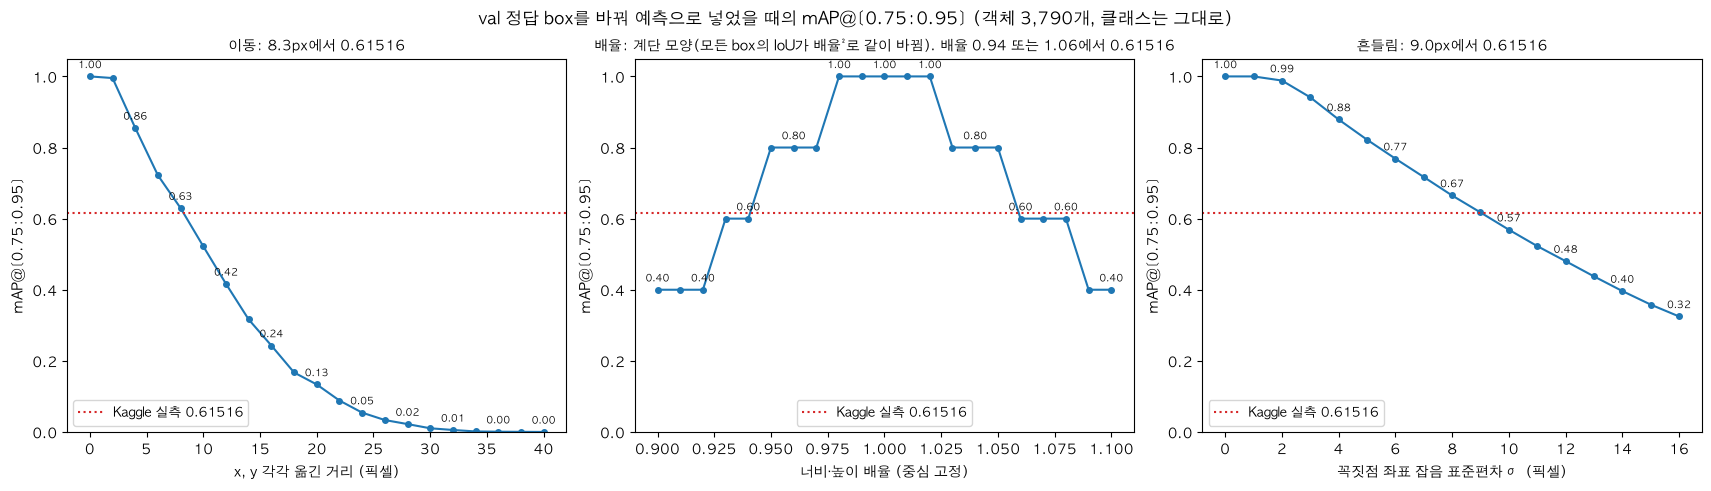

In [ ]:
SHIFTS = np.arange(0, 41, 2)
SCALES = np.round(np.arange(0.90, 1.101, 0.01), 2)
SIGMAS = np.arange(0, 17, 1)
gt_items = [(a['image_id'], a['category_id'], a['bbox']) for a in val_gt['annotations']]


def perturbed(items, shift=0.0, scale=1.0, sigma=0.0, seed=SEED):
    """정답 box를 옮기고(shift), 중심 고정으로 배율을 바꾸고(scale), 꼭짓점 좌표에 잡음(sigma)을 더한 예측 목록을 만든다."""
    noise_rng = np.random.default_rng(seed)
    out = []
    for image_id, c, (x, y, w, h) in items:
        cx, cy = x + w / 2 + shift, y + h / 2 + shift
        nw, nh = w * scale, h * scale
        x1, y1, x2, y2 = cx - nw / 2, cy - nh / 2, cx + nw / 2, cy + nh / 2
        if sigma > 0:
            x1, y1, x2, y2 = np.array([x1, y1, x2, y2]) + noise_rng.normal(0, sigma, 4)
        out.append({'image_id': image_id, 'category_id': c, 'bbox': [x1, y1, max(x2 - x1, 1e-3), max(y2 - y1, 1e-3)], 'score': 1.0})
    return out


def score_of(**kwargs):
    return coco_map(val_gt, perturbed(gt_items, **kwargs), category_ids=COMPETITION)[0]


start = time.perf_counter()
shift_map = np.array([score_of(shift=s) for s in SHIFTS])
scale_map = np.array([score_of(scale=s) for s in SCALES])
sigma_map = np.array([score_of(sigma=s) for s in SIGMAS])
print(f'민감도 계산 {time.perf_counter() - start:.0f}초')


def crossing(xs, ys, level):
    """곡선이 level을 처음 지나는 x를 선형 보간으로 구한다. (ys는 단조 감소를 가정)"""
    for i in range(1, len(xs)):
        if (ys[i - 1] - level) * (ys[i] - level) <= 0:
            return xs[i - 1] + (xs[i] - xs[i - 1]) * (ys[i - 1] - level) / (ys[i - 1] - ys[i])
    return np.nan


level = KAGGLE_SCORES['원본']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout='constrained')
for ax, xs, ys, xlabel, name in ((axes[0], SHIFTS, shift_map, 'x, y 각각 옮긴 거리 (픽셀)', '이동'),
                                 (axes[1], SCALES, scale_map, '너비·높이 배율 (중심 고정)', '배율'),
                                 (axes[2], SIGMAS, sigma_map, '꼭짓점 좌표 잡음 표준편차 σ (픽셀)', '흔들림')):
    ax.plot(xs, ys, marker='o', markersize=4)
    ax.axhline(level, color='tab:red', linestyle=':', linewidth=1.5, label=f'Kaggle 실측 {level}')
    for xi, yi in zip(xs, ys):
        if name == '이동' and xi % 4 == 0 or name == '배율' and round(xi * 100) % 2 == 0 or name == '흔들림' and xi % 2 == 0:
            ax.annotate(f'{yi:.2f}', (xi, yi), fontsize=7, textcoords='offset points', xytext=(0, 6), ha='center')
    if name == '배율':
        left, right = crossing(SCALES[SCALES <= 1][::-1], scale_map[SCALES <= 1][::-1], level), crossing(SCALES[SCALES >= 1], scale_map[SCALES >= 1], level)
        ax.set_title(f'{name}: 계단 모양(모든 box의 IoU가 배율²로 같이 바뀜). 배율 {left:.2f} 또는 {right:.2f}에서 {level}', fontsize=10)
    else:
        ax.set_title(f'{name}: {crossing(xs, ys, level):.1f}px에서 {level}', fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('mAP@[0.75:0.95]')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=9, loc='lower left' if name != '배율' else 'lower center')
fig.suptitle('val 정답 box를 바꿔 예측으로 넣었을 때의 mAP@[0.75:0.95] (객체 3,790개, 클래스는 그대로)')
save_fig(fig, '6-2a_sensitivity')
plt.show()

**인사이트**
- 이동: 2px까지는 1.00, 4px 0.86, 8px 0.63이고 8.3px에서 0.615가 된다. 00 8-2(1차 라벨)의 4px 0.87, 8px 0.64와 같다.
- 배율: 모든 box의 IoU가 배율²로 같이 바뀌므로 곡선이 계단이다. 0.98(IoU 0.960)과 1.02(IoU 0.961)는 아직 1.00이고, 0.94 또는 1.06이 되어야 0.615로 떨어진다.
    - 우리 box가 정답과 같다면 scale0.98 제출은 거의 떨어지지 않아야 한다. 실측은 −0.066이다. 많은 box가 이미 IoU 기준 근처에 걸려 있다는 뜻이고, 이는 정답과 우리 box 사이에 기하학적 불일치가 있다는 직접 증거다.
- 흔들림: 꼭짓점 좌표 잡음 σ 9px에서 0.615가 된다. σ 4px이면 0.88, 16px이면 0.32다.

**결론**
- 0.615는 정답 box가 우리 box에서 x·y로 약 8px 옮겨졌거나, 좌표마다 σ≈9px로 흔들린 것과 같은 크기다. 알약 box 중앙값 크기(약 200px)의 4% 수준이다.
- 어느 쪽인지, 그리고 정답이 조금 큰지는 6-2b에서 진단 제출 3점으로 가른다.

### 6-2b. Kaggle 실측 적합
- "대회 test 정답 = 우리 box에서 어긋난 box"라고 가정하고, 진단 제출과 같은 조작(배율 0.98, 1.00, 1.02)을 예측에 적용했을 때의 점수 3개를 어긋남 크기마다 계산한다.
    - 어긋남 모형 두 가지: 이동(x, y 각각 s px), 흔들림(꼭짓점 좌표 σ px).
    - Kaggle 실측 3점(0.549, 0.615, 0.605)과의 제곱 오차 합이 가장 작은 s와 σ를 찾고, 그 값에서 비대칭(0.98이 1.02보다 훨씬 많이 떨어짐)이 재현되는지 본다.
    - 2변수 모형: 위 어긋남에 더해 정답 box가 우리 box보다 g배(1.005~1.03) 큰 경우도 함께 적합한다. 정답이 조금 크면 1.02는 덜 떨어지고 0.98은 더 떨어진다.
    - 정답 box가 우리 box보다 체계적으로 크거나 작은 모형은 6-2a 배율 곡선이 이미 다룬다. 그 모형에서는 어느 한쪽 배율이 원본보다 올라야 하는데 실측은 둘 다 내려갔다.
- 실행 시간: 약 6분

In [ ]:
TARGET = np.array([KAGGLE_SCORES['scale0.98'], KAGGLE_SCORES['원본'], KAGGLE_SCORES['scale1.02']])
DIAG_SCALES = (0.98, 1.00, 1.02)
FIT_RANGE = np.arange(0, 17, 1)                        # 이동 s, 흔들림 σ (px)
GT_SCALES = (1.00, 1.005, 1.01, 1.015, 1.02, 1.03)     # 2변수 모형: 정답 box가 우리 box보다 g배 큰 경우까지 함께 본다
FIT_RANGE_2D = np.arange(5, 14, 1)


def fit_scores(**offset):
    """정답을 offset만큼 어긋나게 둔 뒤(= 우리 box가 정답에서 offset만큼 어긋난 것과 같다), 우리 box에 진단 배율을 적용한 점수 3개."""
    gt_shifted = {**val_gt, 'annotations': [{**a, 'bbox': p['bbox']} for a, p in zip(val_gt['annotations'], perturbed(gt_items, **offset))]}
    return np.array([coco_map(gt_shifted, perturbed(gt_items, scale=s), category_ids=COMPETITION)[0] for s in DIAG_SCALES])


start = time.perf_counter()
fits = {}   # (모형, 어긋남 크기, 정답 배율 g) → 점수 3개
for s in FIT_RANGE:
    fits[('이동', s, 1.0)] = fit_scores(shift=s)
    fits[('흔들림', s, 1.0)] = fit_scores(sigma=s)
for g in GT_SCALES[1:]:
    for s in FIT_RANGE_2D:
        fits[('이동', s, g)] = fit_scores(shift=s, scale=g)
        fits[('흔들림', s, g)] = fit_scores(sigma=s, scale=g)
print(f'적합 계산 {time.perf_counter() - start:.0f}초 ({len(fits)}개 조합)')
errors = {k: float(np.sum((v - TARGET) ** 2)) for k, v in fits.items()}


def row(label, key):
    v = fits[key]
    asym = f'{(v[0] - v[1]) / (v[2] - v[1]):.1f}' if abs(v[2] - v[1]) > 1e-6 else '-'
    return [label, f'{errors[key]:.4f}', *[f'{x:.3f}' for x in v], f'{v[0] - v[1]:+.3f}', f'{v[2] - v[1]:+.3f}', asym]


rows = [['Kaggle 실측 (v2 rtdetr-l e10)', '-', *[f'{v:.3f}' for v in TARGET], f'{TARGET[0] - TARGET[1]:+.3f}', f'{TARGET[2] - TARGET[1]:+.3f}',
         f'{(TARGET[0] - TARGET[1]) / (TARGET[2] - TARGET[1]):.1f}']]
for model_name, unit in (('이동', 's'), ('흔들림', 'σ')):
    single = {k: e for k, e in errors.items() if k[0] == model_name and k[2] == 1.0}
    best = min(single, key=single.get)
    for s in (best[1] - 1, best[1], best[1] + 1):
        rows.append(row(f'{model_name} {unit}={s}px' + (' (1변수 최적)' if s == best[1] else ''), (model_name, s, 1.0)))
    double = {k: e for k, e in errors.items() if k[0] == model_name and k[2] > 1.0}
    best2 = min(double, key=double.get)
    rows.append(row(f'{model_name} {unit}={best2[1]}px + 정답 배율 {best2[2]:.3f} (2변수 최적)', best2))
show_table(['모형 (정답 = 우리 box에 어긋남을 더한 것)', '제곱 오차 합', '배율 0.98', '배율 1.00', '배율 1.02', '0.98 − 1.00', '1.02 − 1.00', '비대칭 비 (0.98 하락 ÷ 1.02 하락)'], rows)

적합 계산 218초 (124개 조합)


| 모형 (정답 = 우리 box에 어긋남을 더한 것) | 제곱 오차 합 | 배율 0.98 | 배율 1.00 | 배율 1.02 | 0.98 − 1.00 | 1.02 − 1.00 | 비대칭 비 (0.98 하락 ÷ 1.02 하락) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle 실측 (v2 rtdetr-l e10) | - | 0.549 | 0.615 | 0.605 | -0.066 | -0.010 | 6.5 |
| 이동 s=8px | 0.0068 | 0.625 | 0.629 | 0.634 | -0.004 | +0.005 | -1.0 |
| 이동 s=9px (1변수 최적) | 0.0040 | 0.558 | 0.564 | 0.568 | -0.006 | +0.004 | -1.5 |
| 이동 s=10px | 0.0161 | 0.517 | 0.522 | 0.525 | -0.005 | +0.003 | -1.9 |
| 이동 s=9px + 정답 배율 1.030 (2변수 최적) | 0.0028 | 0.543 | 0.570 | 0.577 | -0.028 | +0.007 | -4.0 |
| 흔들림 σ=8px | 0.0124 | 0.642 | 0.665 | 0.641 | -0.023 | -0.024 | 1.0 |
| 흔들림 σ=9px (1변수 최적) | 0.0025 | 0.598 | 0.617 | 0.598 | -0.019 | -0.020 | 1.0 |
| 흔들림 σ=10px | 0.0048 | 0.551 | 0.569 | 0.553 | -0.018 | -0.016 | 1.1 |
| 흔들림 σ=9px + 정답 배율 1.015 (2변수 최적) | 0.0005 | 0.564 | 0.614 | 0.623 | -0.050 | +0.009 | -5.6 |

**인사이트**
- 1변수 모형은 둘 다 비대칭을 재현하지 못한다.
    - 이동 s=9px(오차 0.0040)은 기준 0.564에 0.98이 −0.006, 1.02가 +0.004다. 실측(−0.066, −0.010)의 1/10 크기이고 1.02의 부호가 반대다.
    - 흔들림 σ=9px(오차 0.0025)은 기준 0.617을 맞추지만 0.98·1.02가 −0.019·−0.020으로 대칭이다.
- 2변수 모형 중 흔들림 σ=9px + 정답 배율 1.015가 오차 0.0005로 가장 가깝다. 점수 0.564 / 0.614 / 0.623으로 기준과 0.98의 큰 하락(−0.050, 실측 −0.066)을 재현한다.
    - 1.02는 +0.009로 실측 −0.010과 부호가 다르다. 정답 배율은 1.015보다 작은 1.00~1.01 사이가 맞다(배율 격자가 0.005 간격이라 그 사이를 못 잡았다).
    - 이동 + 정답 배율(오차 0.0028)은 흔들림보다 못하다. 정답 box가 한 방향으로 밀린 것이 아니다.

**결론**
- Kaggle 실측 3점은 "대회 test 정답 box가 우리 box에서 좌표마다 무작위로 σ≈9px 흔들리고, 평균적으로 1% 안팎 크다"로 가장 잘 설명된다.
    - 우리 box는 대회 측 train 라벨(val-Kaggle 0.99, 5-2), AI Hub 라벨(4-2), 1차 모델 box(5-4)와 모두 일치한다. test 정답만 다른 방식으로 만들어졌거나 정밀도가 낮을 가능성이 크고, 그래서 모든 팀이 0.63 아래에 걸려 있다.
- 방향 진단 제출(대각 이동)은 하지 않는다. 이동 모형이 맞지 않으므로 어느 방향으로 옮겨도 점수가 오르지 않는다.
- 배율 1.005~1.01 제출은 기대 이득이 최대 +0.01이다. 원인 분석이 아니라 리더보드용이므로, 한다면 1회만 한다.

### 6-3. 라벨 오류 상한 시뮬레이션
- 대회 측 가공 규칙을 적용한 원본 라벨을 "대회식 정답", 우리 정제 라벨을 "예측(score 1)"으로 넣어 mAP@[0.75:0.95]를 계산한다. test 정답에 원본과 같은 비율의 오류가 남아 있다면 점수가 어디까지 떨어지는지의 추정이다.
    - (a) Kaggle train 232장: `data/raw/train_annotations`(대회 측이 가공해 준 그대로) vs `data/processed/train_annotations`(라벨 누락 추가, bbox 오타 수정)
    - (b) AI Hub 11,974장: `data/external/aihub/raw` 원본에 DATA.md 규칙(bbox 키가 있고 길이 4인 annotation만 유효)을 적용한 정답 vs `data/processed/ai_hub` 정제 라벨
        - 클래스 번호는 두 쪽 모두 `drug_N`(K-코드)으로 둔다. 원본 `dl_idx`는 K-코드 − 1이라 그대로 쓰면 모든 클래스가 0점이 되는데, Kaggle train에서는 대회 측이 K-코드로 맞춰 두었기 때문이다. (3-1)
        - 정제 과정에서 이름이 바뀐 사진(파일명 클래스 오류 13장)과 제외한 사진(35장)은 원본과 이어지지 않아 뺀다.
    - 손실 = 1 − mAP. 클래스 그룹별로도 센다.
- 실행 시간: 약 1~2분 (AI Hub JSON 45,934개 읽기)

In [ ]:
def coco_from_records(records_gt, records_pred, category_ids):
    """(파일명, 클래스)별 라벨 두 묶음을 COCO 정답과 예측으로 만든다. 정답에 없는 파일의 예측은 뺀다."""
    files = sorted({r['file_name'] for r in records_gt.values()})
    image_of = {f: i + 1 for i, f in enumerate(files)}
    gt = {'images': [{'id': image_of[f], 'file_name': f, 'width': IMG_W, 'height': IMG_H} for f in files],
          'annotations': [{'id': i + 1, 'image_id': image_of[r['file_name']], 'category_id': r['category_id'], 'bbox': [float(v) for v in r['bbox']],
                           'area': float(r['bbox'][2] * r['bbox'][3]), 'iscrowd': 0} for i, r in enumerate(records_gt.values())],
          'categories': [{'id': c, 'competition': int(c in COMPETITION)} for c in sorted({r['category_id'] for r in records_gt.values()} | set(category_ids))]}
    preds = [{'image_id': image_of[r['file_name']], 'category_id': r['category_id'], 'bbox': [float(v) for v in r['bbox']], 'score': 1.0}
             for r in records_pred.values() if r['file_name'] in image_of]
    return gt, preds


def valid_by_rule(bbox):
    """DATA.md 가공 규칙: bbox 키가 있고 값이 길이 4인 리스트면 유효."""
    return isinstance(bbox, list) and len(bbox) == 4 and all(isinstance(v, (int, float)) for v in bbox)


start = time.perf_counter()
kaggle_raw = load_annotations(KAGGLE_RAW_ANN)
kaggle_fixed = load_annotations(KAGGLE_FIXED_ANN)
aihub_raw_all = load_annotations(AIHUB_RAW_ANN, aihub=True)
aihub_fixed = load_annotations(AIHUB_FIXED_ANN)
fixed_files = {r['file_name'] for r in aihub_fixed.values()}
raw_files = {r['file_name'] for r in aihub_raw_all.values()}
common_files = fixed_files & raw_files
aihub_raw = {k: r for k, r in aihub_raw_all.items() if r['file_name'] in common_files and valid_by_rule(r['bbox'])}
aihub_raw_invalid = sum(1 for r in aihub_raw_all.values() if r['file_name'] in common_files and not valid_by_rule(r['bbox']))
aihub_fixed_common = {k: r for k, r in aihub_fixed.items() if r['file_name'] in common_files}
print(f'라벨 읽기 {time.perf_counter() - start:.0f}초. AI Hub 공통 사진 {len(common_files):,}장 (정제에만 {len(fixed_files - raw_files)}장, 원본에만 {len(raw_files - fixed_files):,}장), '
      f'규칙에서 걸러진 원본 annotation {aihub_raw_invalid}개')

rows = []
for label, gt_records, pred_records, groups in (('(a) Kaggle train: 대회 측 라벨 vs 우리 정제', kaggle_raw, kaggle_fixed, (('전체', COMPETITION),)),
                                                 ('(b) AI Hub: 원본+가공 규칙 vs 우리 정제', aihub_raw, aihub_fixed_common,
                                                  (('대회 클래스 전체', COMPETITION), ('Kaggle 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)))):
    for group_name, group in groups:
        gt, preds = coco_from_records(gt_records, pred_records, group)
        n_gt = sum(a['category_id'] in group for a in gt['annotations'])
        n_pred = sum(p['category_id'] in group for p in preds)
        if n_gt == 0:
            continue
        precision, _ = coco_precision(gt, preds, category_ids=group)
        aps = ap_by_threshold(precision)
        ap50 = ap_by_threshold(coco_precision(gt, preds, category_ids=group, iou_thresholds=[0.5])[0])[0]
        rows.append([label, group_name, f"{len(gt['images']):,}", f'{n_gt:,}', f'{n_pred:,}', f'{ap50:.4f}', f'{aps.mean():.4f}', f'{1 - aps.mean():.4f}'])
show_table(['시뮬레이션', '클래스 범위', '사진 수', '대회식 정답 객체', '우리 라벨 객체(예측)', 'AP@0.5', 'mAP@[0.75:0.95]', '손실 (1 − mAP)'], rows)

라벨 읽기 14초. AI Hub 공통 사진 11,955장 (정제에만 19장, 원본에만 48장), 규칙에서 걸러진 원본 annotation 144개


| 시뮬레이션 | 클래스 범위 | 사진 수 | 대회식 정답 객체 | 우리 라벨 객체(예측) | AP@0.5 | mAP@[0.75:0.95] | 손실 (1 − mAP) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| (a) Kaggle train: 대회 측 라벨 vs 우리 정제 | 전체 | 232 | 763 | 771 | 0.9881 | 0.9865 | 0.0135 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | 대회 클래스 전체 | 11,947 | 28,365 | 28,464 | 0.9799 | 0.9749 | 0.0251 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | Kaggle 56종 | 11,947 | 21,679 | 21,753 | 0.9803 | 0.9749 | 0.0251 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | test 전용 18종 | 11,947 | 6,686 | 6,711 | 0.9787 | 0.9748 | 0.0252 |

**인사이트**
- (a) Kaggle train 232장: 대회 측 라벨(763개)을 정답으로 두면 우리 정제 라벨(771개)의 mAP@[0.75:0.95]는 0.9865다. 손실 0.0135는 라벨이 빠진 8장과 box 오타 21개(00 2-5)에서 나온다.
- (b) AI Hub 11,947장: 가공 규칙에서 걸러진 annotation 144개를 포함해도 손실은 0.0251(Kaggle 56종 0.0251, test 전용 18종 0.0252)이다. 두 그룹이 같다.
- AP@0.5도 0.980~0.988이라, 손실의 대부분은 IoU 기준이 아니라 "정답에 없거나 box가 완전히 틀린 라벨"에서 온다.

**결론**
- test 정답에 train·AI Hub 원본과 같은 비율의 라벨 오류가 있다면 상한은 0.975~0.987이다. 0.38 손실의 몇 %p만 설명한다.
- 라벨 오류 가설은 주 원인이 아니다. 대회 정답과 우리 box의 체계적 기하 차이(6-2)가 남는다.

### 6-4. 진단 제출 결과 정리
- 2026-11-02~03의 진단 제출 점수에서 클래스 그룹별 평균 AP를 역산하고, 각 제출이 어떤 가설을 판정했는지 적는다.
    - 대회 점수 = (Kaggle 56종 AP 합 + test 전용 18종 AP 합) ÷ 74. 한 그룹만 제출하면 다른 그룹은 0이므로, 그룹 평균 AP = 점수 × 74 ÷ 그룹 크기이다.

In [ ]:
N_CLASSES, N_KAGGLE, N_TEST_ONLY = 74, 56, 18
EXP1_PUBLIC = 0.41  # 1차 RT-DETR(Kaggle train만 학습, test 전용 18종은 예측 못 함)
base = KAGGLE_SCORES['원본']
kaggle_ap = KAGGLE_SCORES['kaggle_only'] * N_CLASSES / N_KAGGLE
test_only_ap = KAGGLE_SCORES['test_only'] * N_CLASSES / N_TEST_ONLY
rows = [
    ['원본 exp2_v2_rtdetr-l_e10', f'{base:.5f}', '-', '기준'],
    ['scale1.02 (너비·높이 +2%)', f"{KAGGLE_SCORES['scale1.02']:.5f}", f"{KAGGLE_SCORES['scale1.02'] - base:+.5f}", '정답 box가 우리보다 크다면 올라야 함 → 내려감. 크기 가설 기각'],
    ['scale0.98 (너비·높이 −2%)', f"{KAGGLE_SCORES['scale0.98']:.5f}", f"{KAGGLE_SCORES['scale0.98'] - base:+.5f}", f"1.02보다 {(KAGGLE_SCORES['scale0.98'] - base) / (KAGGLE_SCORES['scale1.02'] - base):.1f}배 더 내려감. 비대칭은 6-2b에서 해석"],
    ['kaggle_only (56종 예측만)', f"{KAGGLE_SCORES['kaggle_only']:.5f}", f"{KAGGLE_SCORES['kaggle_only'] - base:+.5f}", f'Kaggle 56종 평균 AP = {KAGGLE_SCORES["kaggle_only"]:.5f} × 74 ÷ 56 = {kaggle_ap:.3f}'],
    ['test_only (18종 예측만)', f"{KAGGLE_SCORES['test_only']:.5f}", f"{KAGGLE_SCORES['test_only'] - base:+.5f}", f'test 전용 18종 평균 AP = {KAGGLE_SCORES["test_only"]:.5f} × 74 ÷ 18 = {test_only_ap:.3f}. 0이 아니므로 번호 가설 기각'],
    ['kaggle_only + test_only', f"{KAGGLE_SCORES['kaggle_only'] + KAGGLE_SCORES['test_only']:.5f}", f"{KAGGLE_SCORES['kaggle_only'] + KAGGLE_SCORES['test_only'] - base:+.5f}", '원본과 같음 → Kaggle은 74종 전체 평균(예측 없는 클래스는 0). evaluate.py와 같은 규칙'],
    ['v4 rtdetr-l e5 → score≥0.5만 (팀원)', '0.61558 → 0.61545', '−0.00013', '저신뢰 예측은 점수를 깎지 않음 → 표준 COCO처럼 score 순서를 존중'],
    [f'1차 RT-DETR public (test 전용 0점)', f'{EXP1_PUBLIC:.2f}', '-', f'Kaggle 56종 평균 AP ≈ {EXP1_PUBLIC:.2f} × 74 ÷ 56 = {EXP1_PUBLIC * N_CLASSES / N_KAGGLE:.3f} (test 전용 알약에 낸 오답 포함)'],
]
show_table(['제출', 'Kaggle public', '원본 대비', '해석'], rows)

| 제출 | Kaggle public | 원본 대비 | 해석 |
| --- | --- | --- | --- |
| 원본 exp2_v2_rtdetr-l_e10 | 0.61516 | - | 기준 |
| scale1.02 (너비·높이 +2%) | 0.60500 | -0.01016 | 정답 box가 우리보다 크다면 올라야 함 → 내려감. 크기 가설 기각 |
| scale0.98 (너비·높이 −2%) | 0.54908 | -0.06608 | 1.02보다 6.5배 더 내려감. 비대칭은 6-2b에서 해석 |
| kaggle_only (56종 예측만) | 0.45344 | -0.16172 | Kaggle 56종 평균 AP = 0.45344 × 74 ÷ 56 = 0.599 |
| test_only (18종 예측만) | 0.16171 | -0.45345 | test 전용 18종 평균 AP = 0.16171 × 74 ÷ 18 = 0.665. 0이 아니므로 번호 가설 기각 |
| kaggle_only + test_only | 0.61515 | -0.00001 | 원본과 같음 → Kaggle은 74종 전체 평균(예측 없는 클래스는 0). evaluate.py와 같은 규칙 |
| v4 rtdetr-l e5 → score≥0.5만 (팀원) | 0.61558 → 0.61545 | −0.00013 | 저신뢰 예측은 점수를 깎지 않음 → 표준 COCO처럼 score 순서를 존중 |
| 1차 RT-DETR public (test 전용 0점) | 0.41 | - | Kaggle 56종 평균 AP ≈ 0.41 × 74 ÷ 56 = 0.542 (test 전용 알약에 낸 오답 포함) |

**인사이트**
- kaggle_only + test_only = 0.61515로 원본 0.61516과 같다. Kaggle은 74종 전체 평균을 내며, 예측이 없는 클래스는 0점이다.
- 역산한 그룹 평균 AP는 Kaggle 56종 0.599, test 전용 18종 0.665다. 대회 측 train 라벨로 번호를 확인한 56종과 AI Hub로만 배운 18종이 비슷하게 깎였다.
- 1차 모델(Kaggle train만 학습)의 Kaggle 56종 평균 AP는 약 0.542로, 2차의 0.599와 0.06 차이다. 학습 데이터를 AI Hub로 30배 늘려도 test 점수는 거의 그대로다.
- scale0.98은 −0.066, scale1.02는 −0.010으로 둘 다 떨어졌고 줄인 쪽이 6.5배 더 떨어졌다.

**결론**
- 번호 가설(test 전용 18종 0점), 채점 방식 가설(클래스 평균 방식, 저신뢰 예측 벌점), box 크기 가설(±2%)은 모두 기각한다.
- 손실은 클래스 그룹·모델·학습 데이터와 무관하게 모든 box에 고르게 깔려 있다. 이는 box 하나하나가 정답과 체계적으로 어긋날 때의 모양이다(6-2).

## 7. EDA 결론
- 1~6번의 결과를 항목별 결정 사항으로 정리한다. 괄호 안 번호는 근거가 된 셀의 번호이다.

| 항목 | 결정 | 근거 |
| --- | --- | --- |
| 2차 val | 그대로 쓴다. `val`, `kaggle`, `test_only` 세 점수에 IoU 0.95 AP를 더해 기록한다 | 누수 0 (1-2), 3개 모델 val 0.987~0.995 재현 (5-1), IoU 0.75~0.90은 모두 1.000이라 0.95만 차이가 난다 (5-2) |
| val의 한계 | val 점수로 Kaggle 점수를 예측하지 않는다. val은 "우리 라벨 체계 안의 점수"로만 읽는다 | 74종 중 44종은 val 근거가 AI Hub 정제 라벨뿐이고 val-Kaggle 객체는 5% (2-3). 그 Kaggle 47장도 0.992~0.997 (5-1) |
| 가설 1: val 대표성 | 분포 차이는 있지만 원인이 아니다. val 구성은 바꾸지 않는다 | 비율 순위 상관 0.791, 어긋난 10종은 설계(최소 20개, 상한 20%)의 결과 (2-2). 알약 수·밝기는 val-AI Hub가 test와 가장 가깝다 (4-3) |
| 가설 2: AI Hub category_id | `drug_N` → K-코드 매핑을 유지한다 | AI Hub 원본 dl_idx는 72종 모두 K-코드 − 1, drug_N은 K-코드 (3-1). 18종 외형 일치 (3-2). test_only 제출 0.16171 ≠ 0 (6-4) |
| 가설 3: 클래스별 box 크기 | 출처 간 box 보정을 하지 않는다 | 같은 클래스 크기 분포가 세 출처에서 겹친다 (4-1). 중앙값 비 너비 0.991, 높이 0.998, 짧은 변 0.994 (4-2). 배율 ±2% 제출이 모두 하락 (6-4) |
| 가설 4: train·val 누수 | 없다 | train∩val 조합 Kaggle 0, AI Hub 0, 출처 간 0 (1-2) |
| 채점 코드와 AI Hub 전용 클래스 처리 | 그대로 둔다 | 정답 입력 1.0000, CSV 왕복·독립 구현·무시 규칙 해제 모두 0.9872로 같다. 대회 밖 클래스가 1등인 알약 0개 (6-1). Kaggle도 74종 평균·score 순서 존중 (6-4) |
| 라벨 오류 | 주 원인이 아니다. 라벨 정제는 지금 수준을 유지한다 | 대회 측 train 라벨 기준 손실 0.0135, AI Hub 원본 기준 0.0251 (6-3) |
| 손실 위치 | 대회 test 정답 box가 우리 box에서 좌표마다 무작위로 σ≈9px 흔들리고 1% 안팎 큰 것으로 본다. 모든 팀 공통 상한이다 | 흔들림 σ 9px에서 0.615 (6-2a). 흔들림 σ=9px + 정답 배율 1.015가 진단 3점에 가장 가깝다 (6-2b). Kaggle 56종 0.599, test 전용 0.665로 고르게 깎임 (6-4) |
| 3차 실험 비교 지표 | Kaggle public으로만 개선을 판단한다. 클래스별로는 K-002483, K-019552, K-012778, K-018147을 모니터링한다 | val은 포화 (5-1, 5-3). 검수표 대리 채점도 0.996으로 포화 (5-4) |
| 추가 진단 제출 | 방향 진단(대각 이동)은 하지 않는다 | 이동 모형은 1.02의 부호가 반대 (6-2b) |

**추가 실험 후보**
- 배율 1.005~1.01 제출을 1회만 한다. 0.615보다 오르면 정답이 우리 box보다 약 1% 크다는 것이 확정되고, 기대 이득은 +0.01 이내다.
    - 6-2b의 2변수 최적(정답 배율 1.015)에서 1.02가 +0.009였으므로, 그 이상은 기대하지 않는다.
- 3차 실험(클래스 불균형)은 Kaggle public 차이가 ±0.01 이내면 "효과 없음"으로 결론을 낸다.
    - 정답이 σ≈9px로 흔들리면 box 정밀도를 올려도 점수가 오르지 않는다. 분류 개선도 5-4에서 이미 99.8%라 여지가 없다.
- 대회 측에 test 정답의 생성 방식(원본 AI Hub 라벨 사용 여부, 재가공 여부)을 문의할 수 있으면 한다. 답이 "원본 그대로"면 6-3의 상한(0.975)과 맞지 않으므로 test 정답이 별도로 만들어졌다는 뜻이다.